# AIML ZG519 – NLP Applications
## Assignment 2 – Programming Assignment: Information Extraction (10 Marks)

**File name:** `Assignment2_Programming_Group_81.ipynb`

Keep every section heading in this template. Each part needs code, executed outputs and a short markdown explanation.
Unexecuted or error-producing cells get no credit.

> **Run instructions (Colab):** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.
> Total run time on a free T4 is roughly 35–50 minutes (most of it is the local LLM in Part E).
> Every random step uses `SEED = 42`.

## Group details

| Field | Value |
| --- | --- |
| Group number | 81 |
| Problem statement (PS1–PS7) | PS3 – AI Research Intelligence: Methods, Tasks and Researchers |
| Dataset | CrossRE – AI domain (`DFKI-SLT/cross_re`, config `ai`) |

| # | Member name | BITS ID | Contribution |
| --- | --- | --- | --- |
| 1 | RAJESH R. SHENOI | 2025AE05200 | Equal contribution – all parts |
| 2 | PARUL MITTAL | 2025AE05198 | Equal contribution – all parts |
| 3 | SIDDHARTH KUCHIMANCHI | 2025AE05199 | Equal contribution – all parts |
| 4 | CHAUHAN AYUSH UPENDRA | 2025AE05684 | Equal contribution – all parts |

## Problem statement and objective

An IT services company tracks AI research to decide which techniques to adopt for client projects. Today its
technology‑scouting analysts read papers and articles by hand to find **which methods (algorithms) are used for which
tasks, in which fields, in which products, and who the leading researchers are**. The team wants to automate this by
extracting AI‑domain entities (algorithm, task, field, product, researcher, …) from text and linking them with relations
such as *usage* and *part‑of*, so that a technology map for the consulting practice can be built and kept up to date.

**Objective:** build and compare NER systems of increasing complexity (CRF → BiLSTM‑CRF → fine‑tuned SciBERT → LLM
prompting) on CrossRE‑AI, add a light relation‑extraction step, and recommend – with evidence from the numbers in this
notebook – which approach the organisation should deploy.

## Approach overview

| Step | What we do | Why |
| --- | --- | --- |
| **A. Data** | Load CrossRE‑AI, merge train+validation (450 sentences) for training, keep test (431) untouched. Convert *inclusive* span ends to BIO tags and verify by round‑trip. Hold out 10 % of train+val as a *dev* split only for model selection / loss curves. | The brief asks to train on train+val; a small dev split lets us pick hyper‑parameters and epochs without touching test. |
| **B. CRF** | `sklearn-crfsuite` with word‑shape, case, prefix/suffix, POS and ±2 context features; small `c1/c2` grid and a feature‑group ablation on dev. | Strong, cheap, interpretable classical baseline. |
| **C. BiLSTM‑CRF** | GloVe word embeddings + character CNN → BiLSTM → CRF layer; early stopping on dev; loss curves. | Learns features automatically; char CNN recovers case/morphology lost by lower‑cased GloVe. |
| **D. Transformer** | Fine‑tune `allenai/scibert_scivocab_cased` for token classification with first‑sub‑token label alignment (`-100` elsewhere). | Contextual, domain‑pretrained (scientific text) representations. |
| **E. LLM** | Local open model `Qwen/Qwen2.5-3B-Instruct`, zero‑shot and 5‑shot JSON prompting on a fixed 100‑sentence test sample; JSON mapped back to token spans. | No training data needed; tests how far prompting goes in a niche domain. |
| **F. Relation extraction** | All ordered gold‑entity pairs, top‑5 relations + `OTHER` + capped `NO_RELATION`. Method 1: logistic regression on hand‑crafted features. Method 2: fine‑tuned SciBERT with entity markers. | Classical vs. neural comparison for the "link" step of the technology map. |
| **G. Comparison** | One code‑generated table on the shared 100‑sentence sample, categorised error analysis of the best model, cost/latency, reflection. | Like‑for‑like comparison and an evidence‑based recommendation. |

All NER scores are **entity‑level** precision/recall/F1 from `seqeval` (default CoNLL evaluation; Part G also reports
the strict IOB2 mode).

## 0. Setup

In [1]:
# Install what you need (Colab). Add packages as required.
!pip install -q datasets seqeval sklearn-crfsuite transformers accelerate pytorch-crf nltk

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import random, json, re, os, time, math, copy, warnings
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42          # keep one seed for every random step and state it
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import transformers, datasets, sklearn
print("device:", DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| datasets", datasets.__version__, "| sklearn", sklearn.__version__)

TIMINGS = {}       # model -> {"train_s": ..., "infer_ms_per_sent": ...}; used for the cost discussion in Part G

device: cuda Tesla T4
torch 2.11.0+cu130 | transformers 5.22.0 | datasets 4.8.5 | sklearn 1.6.1


## Part A – Data preparation and EDA (1.0)

Load your PS dataset, convert span annotations to BIO tags, and report:
- sentence and token counts per split
- entity-type distribution
- average entity length in tokens
- 3 example sentences printed with their BIO tags

See the dataset notes in your PS brief (inclusive vs exclusive end indices, character offsets for PS2).

In [3]:
from datasets import load_dataset

# Primary source: the HuggingFace parquet revision named in the PS brief.
# Fallback: the identical JSON files published by the CrossRE authors on GitHub (used only if the Hub is unreachable).
CROSSRE_GITHUB = "https://raw.githubusercontent.com/mainlp/CrossRE/main/crossre_data/ai-{}.json"

def _rows(field):
    # HF can return a sequence-of-dicts either as a list of dicts or as a dict of lists - normalise to list of dicts.
    if isinstance(field, dict):
        keys = list(field)
        return [dict(zip(keys, vals)) for vals in zip(*[field[k] for k in keys])]
    return list(field)

def _label_names(split, column, key):
    # Return ClassLabel names for a nested column (e.g. ner -> entity-type) if it is stored as integers.
    try:
        feat = split.features[column]
        inner = feat.feature if hasattr(feat, "feature") else feat[0]
        lab = inner[key]
        return lab.names if hasattr(lab, "names") else None
    except Exception:
        return None

def _from_hf():
    ds = load_dataset("DFKI-SLT/cross_re", "ai", revision="refs/convert/parquet")
    out = {}
    for name, split in [("train", ds["train"]), ("validation", ds["validation"]), ("test", ds["test"])]:
        ent_names = _label_names(split, "ner", "entity-type")
        rel_names = _label_names(split, "relations", "relation-type")
        recs = []
        for ex in split:
            ner = [(int(e["id-start"]), int(e["id-end"]),
                    ent_names[e["entity-type"]] if ent_names and isinstance(e["entity-type"], int) else e["entity-type"])
                   for e in _rows(ex["ner"])]
            rels = [(int(r["id_1-start"]), int(r["id_1-end"]), int(r["id_2-start"]), int(r["id_2-end"]),
                     rel_names[r["relation-type"]] if rel_names and isinstance(r["relation-type"], int) else r["relation-type"])
                    for r in _rows(ex["relations"])]
            recs.append({"doc_key": ex["doc_key"], "tokens": list(ex["sentence"]), "ner": ner, "relations": rels})
        out[name] = recs
    return out

def _from_github():
    import urllib.request
    out = {}
    for name, fname in [("train", "train"), ("validation", "dev"), ("test", "test")]:
        with urllib.request.urlopen(CROSSRE_GITHUB.format(fname)) as f:
            lines = f.read().decode("utf-8").splitlines()
        recs = []
        for line in lines:
            ex = json.loads(line)
            recs.append({"doc_key": ex["doc_key"], "tokens": ex["sentence"],
                         "ner": [(int(s), int(e), t) for s, e, t in ex["ner"]],
                         "relations": [(int(r[0]), int(r[1]), int(r[2]), int(r[3]), r[4]) for r in ex["relations"]]})
        out[name] = recs
    return out

try:
    raw = _from_hf(); DATA_SOURCE = "HuggingFace DFKI-SLT/cross_re (ai, refs/convert/parquet)"
except Exception as err:
    print("HF Hub not reachable (", type(err).__name__, ") -> using the authors' GitHub copy")
    raw = _from_github(); DATA_SOURCE = "GitHub mainlp/CrossRE crossre_data/ai-*.json"

print("Source:", DATA_SOURCE)
print({k: len(v) for k, v in raw.items()})
ex0 = raw["train"][0]
print(ex0["tokens"][:12], ex0["ner"][:3], ex0["relations"][:2])

HF Hub not reachable ( ValueError ) -> using the authors' GitHub copy
Source: GitHub mainlp/CrossRE crossre_data/ai-*.json
{'train': 100, 'validation': 350, 'test': 431}
['Popular', 'approaches', 'of', 'opinion-based', 'recommender', 'system', 'utilize', 'various', 'techniques', 'including', 'text', 'mining'] [(3, 5, 'product'), (10, 11, 'field'), (13, 14, 'task')] [(3, 5, 10, 11, 'part-of'), (3, 5, 10, 11, 'usage')]


In [4]:
def spans_to_bio(n_tokens, spans):
    """spans: list of (start, end_exclusive, type) in TOKEN indices.
    Returns a list of BIO tags. Convert inclusive ends (CrossRE) to exclusive before calling."""
    tags = ["O"] * n_tokens
    for start, end, etype in spans:
        tags[start] = f"B-{etype}"
        for i in range(start + 1, end):
            tags[i] = f"I-{etype}"
    return tags

def bio_to_spans(tags):
    """Inverse of spans_to_bio: returns (start, end_exclusive, type). A stray I- tag starts a new entity (CoNLL rule)."""
    spans, start, etype = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):
        if t == "O" or t.startswith("B-") or (t.startswith("I-") and t[2:] != etype):
            if start is not None:
                spans.append((start, i, etype))
            start, etype = (i, t[2:]) if t != "O" else (None, None)
    return spans

# Sanity check
print(spans_to_bio(6, [(0, 2, "PER"), (4, 5, "LOC")]))
print(bio_to_spans(spans_to_bio(6, [(0, 2, "PER"), (4, 5, "LOC")])))

['B-PER', 'I-PER', 'O', 'O', 'B-LOC', 'O']
[(0, 2, 'PER'), (4, 5, 'LOC')]


In [5]:
def prepare(records):
    out = []
    for r in records:
        n = len(r["tokens"])
        spans_excl = [(s, e + 1, t) for s, e, t in r["ner"]]           # CrossRE end index is INCLUSIVE -> +1
        tags = spans_to_bio(n, spans_excl)
        # Some entity pairs carry two relation labels (e.g. part-of AND usage): keep the FIRST annotated one.
        rel, n_dup = {}, 0
        for s1, e1, s2, e2, lab in r["relations"]:
            key = (s1, e1, s2, e2)
            if key in rel:
                n_dup += 1
                continue
            rel[key] = lab
        out.append({"doc_key": r["doc_key"], "tokens": r["tokens"], "tags": tags,
                    "spans": sorted(r["ner"]), "relations": rel, "n_dup_rel": n_dup})
    return out

splits = {k: prepare(v) for k, v in raw.items()}

# Verification of the BIO conversion on EVERY sentence: BIO -> spans must give back the gold spans exactly.
for name, data in splits.items():
    bad = sum(bio_to_spans(d["tags"]) != sorted((s, e + 1, t) for s, e, t in d["spans"]) for d in data)
    print(f"{name:<10} round-trip mismatches: {bad}")

train_data = splits["train"] + splits["validation"]          # brief: train on train + validation combined
test_data = splits["test"]
train_tokens = [d["tokens"] for d in train_data]; train_tags = [d["tags"] for d in train_data]
test_tokens = [d["tokens"] for d in test_data];   test_tags = [d["tags"] for d in test_data]

# A 10 % dev split of train+val, used ONLY for model selection / loss curves (never the test set).
_idx = list(range(len(train_data))); random.Random(SEED).shuffle(_idx)
dev_ids = sorted(_idx[: len(_idx) // 10]); fit_ids = sorted(_idx[len(_idx) // 10:])
print(f"train+val = {len(train_data)} sentences  ->  fit {len(fit_ids)} / dev {len(dev_ids)};  test = {len(test_data)}")

train      round-trip mismatches: 0
validation round-trip mismatches: 0
test       round-trip mismatches: 0
train+val = 450 sentences  ->  fit 405 / dev 45;  test = 431


,sentences,tokens,entities,avg tokens/sent,avg entities/sent,max tokens/sent,relations (first label),dropped duplicate labels
split,,,,,,,,
train,100,3782,532,37.8,5.32,73,350,13
validation,350,10919,1548,31.2,4.42,83,1006,73
test,431,12991,1811,30.1,4.20,84,1127,37
train+val,450,14701,2080,32.7,4.62,83,1356,86


split,train,validation,test,train+val,train+val %,avg len (tokens)
type,,,,,,
algorithm,80,178,179,258,12.4,2.09
misc,45,186,186,231,11.1,2.33
product,57,174,198,231,11.1,1.88
field,39,177,205,216,10.4,1.90
task,59,146,219,205,9.9,2.21
researcher,54,142,158,196,9.4,1.87
metrics,27,146,191,173,8.3,2.11
organisation,50,95,148,145,7.0,2.68
conference,24,83,86,107,5.1,3.40


Average entity length (tokens): test=2.09, train=2.20, validation=2.16
15 entity types seen in train+val: ['academicjournal', 'algorithm', 'conference', 'country', 'field', 'location', 'metrics', 'misc', 'organisation', 'person', 'product', 'programlang', 'researcher', 'task', 'university']
Types that appear ONLY in test (no model can learn them): ['event']


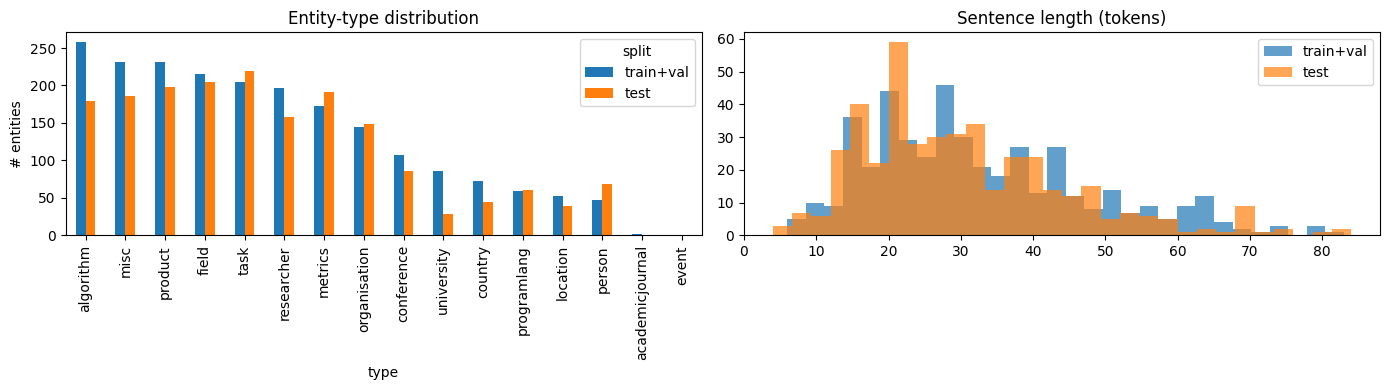

In [6]:
# ---------- EDA: counts per split ----------
rows = []
for name, data in list(splits.items()) + [("train+val", train_data)]:
    n_tok = sum(len(d["tokens"]) for d in data)
    n_ent = sum(len(d["spans"]) for d in data)
    rows.append({"split": name, "sentences": len(data), "tokens": n_tok, "entities": n_ent,
                 "avg tokens/sent": round(n_tok / len(data), 1), "avg entities/sent": round(n_ent / len(data), 2),
                 "max tokens/sent": max(len(d["tokens"]) for d in data),
                 "relations (first label)": sum(len(d["relations"]) for d in data),
                 "dropped duplicate labels": sum(d["n_dup_rel"] for d in data)})
eda_counts = pd.DataFrame(rows).set_index("split")
display(eda_counts)

# ---------- entity-type distribution and average entity length ----------
def ent_df(data, split):
    return pd.DataFrame([{"split": split, "type": t, "len": e - s + 1} for d in data for s, e, t in d["spans"]])
ents = pd.concat([ent_df(splits[k], k) for k in splits])
dist = ents.pivot_table(index="type", columns="split", values="len", aggfunc="count", fill_value=0)[["train", "validation", "test"]]
dist["train+val"] = dist["train"] + dist["validation"]
dist["train+val %"] = (100 * dist["train+val"] / dist["train+val"].sum()).round(1)
dist["avg len (tokens)"] = ents.groupby("type")["len"].mean().round(2)
dist = dist.sort_values("train+val", ascending=False)
display(dist)
print("Average entity length (tokens): " + ", ".join(f"{k}={v:.2f}" for k, v in ents.groupby("split")["len"].mean().items()))
ENTITY_TYPES = sorted({t for d in train_data for _, _, t in d["spans"]})
unseen = sorted({t for d in test_data for _, _, t in d["spans"]} - set(ENTITY_TYPES))
print(f"{len(ENTITY_TYPES)} entity types seen in train+val:", ENTITY_TYPES)
print("Types that appear ONLY in test (no model can learn them):", unseen)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
dist[["train+val", "test"]].plot.bar(ax=axes[0], title="Entity-type distribution")
axes[0].set_ylabel("# entities")
axes[1].hist([len(d["tokens"]) for d in train_data], bins=30, alpha=.7, label="train+val")
axes[1].hist([len(d["tokens"]) for d in test_data], bins=30, alpha=.7, label="test")
axes[1].set_title("Sentence length (tokens)"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/eda.png", dpi=120); plt.show()

In [7]:
# ---------- 3 example sentences with BIO tags (verification of the inclusive-end conversion) ----------
def show_tagged(d, max_tokens=40):
    print(d["doc_key"], "| gold spans (start, end_INCLUSIVE, type):", d["spans"][:6], "..." if len(d["spans"]) > 6 else "")
    print("  ", " ".join(f"{w}/{t}" for w, t in list(zip(d["tokens"], d["tags"]))[:max_tokens]))
    for s, e, t in d["spans"][:6]:
        print(f"     tokens[{s}..{e}] = {' '.join(d['tokens'][s:e+1])!r:45} -> {d['tags'][s:e+1]}")
    print()

for i in [0, 3, 120]:
    show_tagged(train_data[i])

ai-train-1 | gold spans (start, end_INCLUSIVE, type): [(3, 5, 'product'), (10, 11, 'field'), (13, 14, 'task'), (16, 17, 'task'), (21, 23, 'task'), (26, 27, 'field')] ...
   Popular/O approaches/O of/O opinion-based/B-product recommender/I-product system/I-product utilize/O various/O techniques/O including/O text/B-field mining/I-field ,/O information/B-task retrieval/I-task ,/O sentiment/B-task analysis/I-task (/O see/O also/O Multimodal/B-task sentiment/I-task analysis/I-task )/O and/O deep/B-field learning/I-field X.Y./B-researcher Feng/I-researcher ,/O H./B-researcher Zhang/I-researcher ,/O Y.J./B-researcher Ren/I-researcher ,/O P.H./B-researcher Shang/I-researcher ,/O
     tokens[3..5] = 'opinion-based recommender system'            -> ['B-product', 'I-product', 'I-product']
     tokens[10..11] = 'text mining'                                 -> ['B-field', 'I-field']
     tokens[13..14] = 'information retrieval'                       -> ['B-task', 'I-task']
     tokens[16..17] = 's

**Data preparation decisions**

* **Inclusive ends.** CrossRE stores `(start, end, type)` with an *inclusive* end, so every span is converted with
  `end + 1` before `spans_to_bio`. The conversion is verified twice: (i) the round‑trip `BIO → spans` reproduces the gold
  spans for **every** sentence in all three splits (0 mismatches printed above), and (ii) three sentences are printed
  with their tags, and every span’s tokens line up with a `B‑…, I‑…` run.
* **Splits.** As instructed, train + validation (100 + 350 = 450 sentences) is the training set and the 431‑sentence
  test split is used only for final evaluation. 10 % of train+val (45 sentences, seed 42) is held out as a *dev* split
  for hyper‑parameter / epoch selection and loss curves; after selection the BiLSTM and transformer are refit on all
  450 sentences.
* **Duplicate relation labels.** Some entity pairs are annotated with two relations (e.g. `part-of` **and** `usage`);
  we keep the *first* annotated label (count of dropped labels shown in the table).
* **Source.** The loader tries the HF parquet revision named in the brief first; if the Hub copy cannot be read in
  the runtime (the printed source line says which was used) it reads the identical JSON files published by the
  CrossRE authors. The split sizes printed above (100 / 350 / 431) match the brief exactly.
* No entity spans overlap, so flat BIO tagging loses nothing.

**What the EDA shows**

* **Very small training set**: only 450 sentences / 14.7 k tokens for **15 entity types** (≈ 100 examples per type
  on average). This favours models that bring prior knowledge (pre‑trained embeddings / SciBERT / LLMs).
* **Long, dense sentences**: 32.7 tokens and 4.6 entities per sentence on average (max 83 tokens) – much denser than news NER.
* **Class imbalance**: `misc`, `algorithm`, `field`, `product`, `task` dominate, while `person` (47), `location` (52),
  `academicjournal` (2) are rare. `event` appears **only in test**, so every model must miss it.
* **Train/test shift**: the test set is relatively richer in `metrics`, `task`, `organisation` and `person`, which
  will hurt recall on those types.
* Entities average ~2.2 tokens, but `conference` (3.4), `organisation` and `university` (≈2.7), `misc` and `task`
  (≈2.2–2.3) are often multi‑word spans, where boundary errors are likely.
* Fine‑grained, overlapping semantics (`researcher` vs `person`, `university` vs `organisation`, `algorithm` vs
  `product`/`misc`) foreshadow **type confusion** errors.

## Part B – Classical NER: CRF (1.5)

Train a CRF with hand-crafted features (word shape, case, prefix/suffix, POS, neighbouring words). Justify the features.
Report entity-level P/R/F1 per type with seqeval.

In [8]:
import nltk
for pkg in ["averaged_perceptron_tagger_eng", "averaged_perceptron_tagger"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception:
        pass

def pos_tags(tokens):
    return [p for _, p in nltk.pos_tag(tokens)]

for d in train_data + test_data:            # POS-tag once and cache
    d["pos"] = pos_tags(d["tokens"])
print(list(zip(train_data[0]["tokens"][:10], train_data[0]["pos"][:10])))

[('Popular', 'JJ'), ('approaches', 'NNS'), ('of', 'IN'), ('opinion-based', 'JJ'), ('recommender', 'NN'), ('system', 'NN'), ('utilize', 'VBP'), ('various', 'JJ'), ('techniques', 'NNS'), ('including', 'VBG')]


In [9]:
import sklearn_crfsuite
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from seqeval.scheme import IOB2

def shape(w):
    s = re.sub(r"[A-Z]", "X", w); s = re.sub(r"[a-z]", "x", s); s = re.sub(r"[0-9]", "d", s)
    return s

def short_shape(w):                       # collapse repeats: "Convolutional" -> "Xx", "CNN-2" -> "X-d"
    return re.sub(r"(.)\1+", r"\1", shape(w))

FEATURE_GROUPS = {"lexical", "case", "shape", "affix", "pos", "context"}

def token_feats(w, pos, prefix, groups):
    f = {}
    if "lexical" in groups:
        f[prefix + "word.lower"] = w.lower()
    if "case" in groups:
        f[prefix + "istitle"] = w.istitle(); f[prefix + "isupper"] = w.isupper()
        f[prefix + "has_upper_inside"] = any(c.isupper() for c in w[1:])       # camelCase: TensorFlow, ImageNet
    if "shape" in groups:
        f[prefix + "shape"] = short_shape(w)
    if "pos" in groups:
        f[prefix + "pos"] = pos; f[prefix + "pos2"] = pos[:2]
    return f

def word2features(sent, i, pos=None, groups=FEATURE_GROUPS):
    w = sent[i]
    pos = pos or ["NN"] * len(sent)
    feats = {"bias": 1.0}
    feats.update(token_feats(w, pos[i], "", groups))
    if "shape" in groups:
        feats.update({"len": min(len(w), 12), "isdigit": w.isdigit(), "has_digit": any(c.isdigit() for c in w),
                      "has_hyphen": "-" in w, "is_punct": bool(re.fullmatch(r"\W+", w)), "full_shape": shape(w)[:8]})
    if "affix" in groups:
        for k in (2, 3, 4):
            feats[f"prefix{k}"] = w[:k].lower(); feats[f"suffix{k}"] = w[-k:].lower()
    if "context" in groups:
        for off in (-2, -1, 1, 2):
            j = i + off
            if 0 <= j < len(sent):
                feats.update(token_feats(sent[j], pos[j], f"{off:+d}:", groups - {"context"}))
            else:
                feats[f"{off:+d}:" + ("BOS" if j < 0 else "EOS")] = True
        if 0 < i:
            feats["bigram-1"] = sent[i - 1].lower() + "|" + w.lower()
        if i < len(sent) - 1:
            feats["bigram+1"] = w.lower() + "|" + sent[i + 1].lower()
    return feats

def sent2features(sent, pos=None, groups=FEATURE_GROUPS):
    return [word2features(sent, i, pos, groups) for i in range(len(sent))]

print(json.dumps(word2features(train_data[0]["tokens"], 4, train_data[0]["pos"]), indent=None)[:900], "...")

{"bias": 1.0, "word.lower": "recommender", "istitle": false, "isupper": false, "has_upper_inside": false, "shape": "x", "pos": "NN", "pos2": "NN", "len": 11, "isdigit": false, "has_digit": false, "has_hyphen": false, "is_punct": false, "full_shape": "xxxxxxxx", "prefix2": "re", "suffix2": "er", "prefix3": "rec", "suffix3": "der", "prefix4": "reco", "suffix4": "nder", "-2:word.lower": "of", "-2:istitle": false, "-2:isupper": false, "-2:has_upper_inside": false, "-2:shape": "x", "-2:pos": "IN", "-2:pos2": "IN", "-1:word.lower": "opinion-based", "-1:istitle": false, "-1:isupper": false, "-1:has_upper_inside": false, "-1:shape": "x-x", "-1:pos": "JJ", "-1:pos2": "JJ", "+1:word.lower": "system", "+1:istitle": false, "+1:isupper": false, "+1:has_upper_inside": false, "+1:shape": "x", "+1:pos": "NN", "+1:pos2": "NN", "+2:word.lower": "utilize", "+2:istitle": false, "+2:isupper": false, "+2:has_ ...


In [10]:
def train_crf(data, groups=FEATURE_GROUPS, c1=0.1, c2=0.1, max_iter=200):
    crf = sklearn_crfsuite.CRF(algorithm="lbfgs", c1=c1, c2=c2, max_iterations=max_iter, all_possible_transitions=True)
    crf.fit([sent2features(d["tokens"], d["pos"], groups) for d in data], [d["tags"] for d in data])
    return crf

def crf_predict(crf, data, groups=FEATURE_GROUPS):
    return crf.predict([sent2features(d["tokens"], d["pos"], groups) for d in data])

fit_set = [train_data[i] for i in fit_ids]; dev_set = [train_data[i] for i in dev_ids]
dev_tags = [d["tags"] for d in dev_set]

# 1) small regularisation grid on the dev split (all features)
grid = []
for c1, c2 in [(0.0, 0.1), (0.05, 0.05), (0.1, 0.1), (0.2, 0.05), (0.05, 0.3)]:
    m = train_crf(fit_set, c1=c1, c2=c2)
    grid.append({"c1": c1, "c2": c2, "dev F1": f1_score(dev_tags, crf_predict(m, dev_set))})
grid = pd.DataFrame(grid); display(grid.round(4))
best_c = grid.loc[grid["dev F1"].idxmax()]; C1, C2 = float(best_c.c1), float(best_c.c2)
print(f"selected c1={C1}, c2={C2}")

# 2) feature-group ablation on dev (remove one group at a time) -> justifies the feature set
abl = [{"features": "ALL", "dev F1": float(best_c["dev F1"])}]
for g in sorted(FEATURE_GROUPS):
    groups = FEATURE_GROUPS - {g}
    m = train_crf(fit_set, groups=groups, c1=C1, c2=C2)
    abl.append({"features": f"without {g}", "dev F1": f1_score(dev_tags, crf_predict(m, dev_set, groups))})
abl = pd.DataFrame(abl); abl["delta vs ALL"] = abl["dev F1"] - abl.loc[0, "dev F1"]
display(abl.round(4))

,c1,c2,dev F1
0,0.00,0.10,0.5773
1,0.05,0.05,0.5903
2,0.10,0.10,0.5939
3,0.20,0.05,0.5700
4,0.05,0.30,0.5758


selected c1=0.1, c2=0.1


,features,dev F1,delta vs ALL
0,ALL,0.5939,0.0000
1,without affix,0.5573,-0.0366
2,without case,0.5714,-0.0225
3,without context,0.5436,-0.0503
4,without lexical,0.5758,-0.0182
5,without pos,0.5788,-0.0151
6,without shape,0.5831,-0.0108


In [11]:
# 3) final CRF on all of train+val, evaluated on the full test split
t0 = time.perf_counter()
crf = train_crf(train_data, c1=C1, c2=C2)
crf_train_s = time.perf_counter() - t0
t0 = time.perf_counter()
y_pred_crf = crf_predict(crf, test_data)
TIMINGS["CRF"] = {"train_s": crf_train_s, "infer_ms_per_sent": 1000 * (time.perf_counter() - t0) / len(test_data)}
y_test = test_tags
print(f"CRF trained in {crf_train_s:.1f}s | test P={precision_score(y_test, y_pred_crf):.4f} "
      f"R={recall_score(y_test, y_pred_crf):.4f} F1={f1_score(y_test, y_pred_crf):.4f}")

CRF trained in 23.8s | test P=0.6134 R=0.5511 F1=0.5806


In [12]:
print(classification_report(y_test, y_pred_crf, digits=4, zero_division=0))

# What did the CRF learn? strongest state features and transitions
sf = sorted(crf.state_features_.items(), key=lambda kv: -kv[1])
print("Top positive state features:")
for (attr, label), w in sf[:15]:
    print(f"  {w:7.3f}  {label:16} {attr}")
tr = sorted(crf.transition_features_.items(), key=lambda kv: kv[1])
print("Most forbidden transitions:", [(f"{a}->{b}", round(w, 2)) for (a, b), w in tr[:5]])

                 precision    recall  f1-score   support

academicjournal     0.0000    0.0000    0.0000         1
      algorithm     0.5531    0.5531    0.5531       179
     conference     0.6125    0.5698    0.5904        86
        country     0.5185    0.6364    0.5714        44
          event     0.0000    0.0000    0.0000         1
          field     0.8093    0.7659    0.7870       205
       location     0.7500    0.4615    0.5714        39
        metrics     0.7558    0.6806    0.7163       191
           misc     0.2951    0.1935    0.2338       186
   organisation     0.5688    0.4189    0.4825       148
         person     0.3043    0.1029    0.1538        68
        product     0.5269    0.4949    0.5104       198
    programlang     0.7500    0.6500    0.6964        60
     researcher     0.5915    0.7975    0.6792       158
           task     0.7033    0.5845    0.6384       219
     university     0.5676    0.7500    0.6462        28

      micro avg     0.6134   

**Feature justification**

| Group | Features | Why it should help on AI text |
| --- | --- | --- |
| lexical | lower‑cased word | memorises frequent entity words (*learning*, *recognition*, *network*) |
| case | `istitle`, `isupper`, inner capital | researcher names, conferences, products (*TensorFlow*, *ImageNet*) are capitalised; acronyms (*CNN*, *IJCAI*) are all‑caps |
| shape | collapsed shape (`Xx`, `X`, `x-x`), digits, hyphen, length | generalises to unseen words with the same look (*ResNet‑50* → `Xx-d`), years/numbers are rarely entities |
| affix | prefixes/suffixes of length 2–4 | morphology: *‑ing / ‑tion* (tasks), *‑ics / ‑ogy* (fields), *‑er* (products, *encoder*) |
| POS | NLTK Penn tag + coarse tag | entities are mostly noun phrases (NN/NNP/JJ) – helps boundaries |
| context | the above for words at ±1, ±2, and word bigrams | *“… proposed by X”*, *“… for X”* cue the type; neighbours fix B/I boundaries of multi‑word spans |

The `c1/c2` grid and the ablation table above are computed on the dev split (never on test).

**Results** (numbers from the executed cells above – re‑check after the final Colab run).

* **Which features helped (ablation on dev):** removing the **context** window hurts most (−0.050 F1), then **affixes**
  (−0.037), **case** (−0.023), the **word itself** (−0.018), **POS** (−0.015) and **shape** (−0.011). Every group
  contributes, so all are kept. Context matters most because AI entities are often signalled by the surrounding phrase
  (*“… in **field**”*, *“… error **rate**”* → `metrics`), which the learned state features above confirm
  (`B-location ← -1:in`, `B-metrics ← -2:rate/error`, `B-field ← suffix "ics"`). The strongly negative `O → I‑X`
  transitions show the CRF has learned valid BIO structure.
* **Test (full split): P 0.613 / R 0.551 / F1 0.581.** Best types: `field` (0.787), `metrics` (0.716),
  `programlang` (0.696), `researcher` (0.679) – frequent or with distinctive surface cues (suffixes, capitalised
  names, a small closed set of languages).
* **Handled poorly:** `person` (0.154 – confused with `researcher`, only 47 training examples), `misc` (0.234 – a
  heterogeneous catch‑all with no consistent surface pattern), `organisation` (0.483, recall 0.42 – confused with
  `university`/`product`), plus `academicjournal`/`event` (≈ 0–2 training examples → 0). Precision is higher than recall:
  the CRF is conservative and misses entities whose words never occurred in training.

## Part C – Deep learning NER: BiLSTM / BiLSTM-CRF (1.5)

Use pretrained word embeddings (GloVe or similar). Plot training and validation loss. Report seqeval P/R/F1 per type.

In [13]:
import zipfile, urllib.request
from torchcrf import CRF

GLOVE_DIM = 100
GLOVE_TXT = f"glove.6B.{GLOVE_DIM}d.txt"

def _extract(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        z.extract(GLOVE_TXT, ".")

def get_glove():
    """Return (word->vector dict, source). Tries the HF mirror first (fast on Colab), then Stanford NLP."""
    if not os.path.exists(GLOVE_TXT):
        try:
            from huggingface_hub import hf_hub_download
            _extract(hf_hub_download(repo_id="stanfordnlp/glove", filename="glove.6B.zip"))
        except Exception as e1:
            print("HF mirror failed:", type(e1).__name__, "-> trying nlp.stanford.edu (822 MB, a few minutes)")
            try:
                urllib.request.urlretrieve("https://nlp.stanford.edu/data/glove.6B.zip", "glove.6B.zip")
                _extract("glove.6B.zip")
            except Exception as e2:
                print("Stanford download failed:", type(e2).__name__)
                return {}, "NONE"
    vecs = {}
    with open(GLOVE_TXT, encoding="utf8") as f:
        for line in f:
            parts = line.rstrip().split(" ")
            vecs[parts[0]] = np.asarray(parts[1:], dtype=np.float32)
    return vecs, f"GloVe 6B {GLOVE_DIM}d"

glove, GLOVE_SOURCE = get_glove()
print(f"{GLOVE_SOURCE}: {len(glove):,} vectors")
if not glove:
    print("WARNING: no pretrained embeddings could be downloaded - the model below falls back to random init. "
          "The brief requires pretrained embeddings, so fix the download before submitting.")

glove.6B.zip: reconstructing file:   0%|          |  0.00B /  862MB            

glove.6B.zip: downloading bytes:           |  0.00B            

GloVe 6B 100d: 400,001 vectors


In [14]:
def norm_word(w):
    return re.sub(r"\d", "0", w.lower())

# Vocabulary: every training word + every GloVe word that occurs in the corpus text (vectors are unsupervised,
# no test labels are used). Unknown words -> <unk>.
word_counts = Counter(norm_word(w) for d in train_data for w in d["tokens"])
corpus_words = {norm_word(w) for d in train_data + test_data for w in d["tokens"]}
vocab = ["<pad>", "<unk>"] + sorted(set(word_counts) | {w for w in corpus_words if w in glove})
word2id = {w: i for i, w in enumerate(vocab)}
chars = ["<pad>", "<unk>"] + sorted({c for d in train_data for w in d["tokens"] for c in w})
char2id = {c: i for i, c in enumerate(chars)}
tag_list = ["O"] + sorted({t for tags in train_tags for t in tags} - {"O"})
tag2id = {t: i for i, t in enumerate(tag_list)}; id2tag = {i: t for t, i in tag2id.items()}

rng_np = np.random.RandomState(SEED)
emb_matrix = rng_np.normal(0, 0.1, (len(vocab), GLOVE_DIM)).astype(np.float32); emb_matrix[0] = 0
hits = 0
for w, i in word2id.items():
    if w in glove:
        emb_matrix[i] = glove[w]; hits += 1
test_cov = np.mean([norm_word(w) in glove for d in test_data for w in d["tokens"]])
print(f"vocab={len(vocab):,}  chars={len(chars)}  tags={len(tag_list)}  GloVe hits={hits:,}  "
      f"test-token GloVe coverage={test_cov:.1%}")

vocab=4,752  chars=105  tags=31  GloVe hits=4,469  test-token GloVe coverage=97.5%


In [15]:
class BiLSTMCRF(torch.nn.Module):
    def __init__(self, emb_matrix, n_chars, n_tags, char_dim=30, char_filters=50, hidden=200, dropout=0.5):
        super().__init__()
        self.word_emb = torch.nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.char_emb = torch.nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.char_cnn = torch.nn.Conv1d(char_dim, char_filters, kernel_size=3, padding=1)
        self.dropout = torch.nn.Dropout(dropout)
        self.lstm = torch.nn.LSTM(emb_matrix.shape[1] + char_filters, hidden // 2, batch_first=True, bidirectional=True)
        self.proj = torch.nn.Linear(hidden, n_tags)
        self.crf = CRF(n_tags, batch_first=True)

    def emissions(self, words, chars):
        B, T, L = chars.shape
        c = self.char_emb(chars.view(B * T, L)).transpose(1, 2)            # (B*T, char_dim, L)
        c = torch.relu(self.char_cnn(c)).max(dim=2).values.view(B, T, -1)    # max-pool over characters
        x = self.dropout(torch.cat([self.word_emb(words), c], dim=-1))
        h, _ = self.lstm(x)
        return self.proj(self.dropout(h))

    def loss(self, words, chars, tags, mask):
        return -self.crf(self.emissions(words, chars), tags, mask=mask, reduction="mean")

    def decode(self, words, chars, mask):
        return self.crf.decode(self.emissions(words, chars), mask=mask)

def make_batch(batch, with_tags=True):
    T = max(len(d["tokens"]) for d in batch); L = min(20, max(len(w) for d in batch for w in d["tokens"]))
    W = torch.zeros(len(batch), T, dtype=torch.long); C = torch.zeros(len(batch), T, L, dtype=torch.long)
    Y = torch.zeros(len(batch), T, dtype=torch.long); M = torch.zeros(len(batch), T, dtype=torch.bool)
    for b, d in enumerate(batch):
        for t, w in enumerate(d["tokens"]):
            W[b, t] = word2id.get(norm_word(w), 1); M[b, t] = True
            for k, ch in enumerate(w[:L]):
                C[b, t, k] = char2id.get(ch, 1)
            if with_tags:
                Y[b, t] = tag2id[d["tags"][t]]
    return W.to(DEVICE), C.to(DEVICE), Y.to(DEVICE), M.to(DEVICE)

def lstm_predict(model, data, bs=64):
    model.eval(); preds = []
    with torch.no_grad():
        for i in range(0, len(data), bs):
            W, C, _, M = make_batch(data[i:i + bs], with_tags=False)
            preds += [[id2tag[t] for t in seq] for seq in model.decode(W, C, M)]
    return preds

def lstm_loss(model, data, bs=64):
    model.eval(); tot = 0.0
    with torch.no_grad():
        for i in range(0, len(data), bs):
            W, C, Y, M = make_batch(data[i:i + bs]); tot += model.loss(W, C, Y, M).item() * len(data[i:i + bs])
    return tot / len(data)

def train_bilstm(train_set, epochs, dev=None, bs=16, lr=1e-3, patience=10, seed=SEED):
    torch.manual_seed(seed); rng = random.Random(seed)
    model = BiLSTMCRF(emb_matrix, len(chars), len(tag_list)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist, best, best_state, bad = [], -1, None, 0
    order = list(range(len(train_set)))
    for ep in range(1, epochs + 1):
        model.train(); rng.shuffle(order); tot = 0.0
        for i in range(0, len(order), bs):
            batch = [train_set[j] for j in order[i:i + bs]]
            W, C, Y, M = make_batch(batch)
            loss = model.loss(W, C, Y, M)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
            tot += loss.item() * len(batch)
        rec = {"epoch": ep, "train_loss": tot / len(train_set)}
        if dev is not None:
            rec["val_loss"] = lstm_loss(model, dev)
            rec["val_f1"] = f1_score([d["tags"] for d in dev], lstm_predict(model, dev))
            if rec["val_f1"] > best:
                best, best_state, bad = rec["val_f1"], copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
        hist.append(rec)
        if dev is not None and bad >= patience:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

# Phase 1: train on the fit split, early-stop on dev F1 -> learning curves + best epoch
lstm_sel, lstm_hist = train_bilstm(fit_set, epochs=80, dev=dev_set)
BEST_LSTM_EPOCH = int(lstm_hist.loc[lstm_hist["val_f1"].idxmax(), "epoch"])
print(f"best dev F1 = {lstm_hist['val_f1'].max():.4f} at epoch {BEST_LSTM_EPOCH}")

# Phase 2: refit on ALL train+val for the selected number of epochs
t0 = time.perf_counter()
lstm_model, _ = train_bilstm(train_data, epochs=BEST_LSTM_EPOCH)
lstm_train_s = time.perf_counter() - t0

best dev F1 = 0.6355 at epoch 42


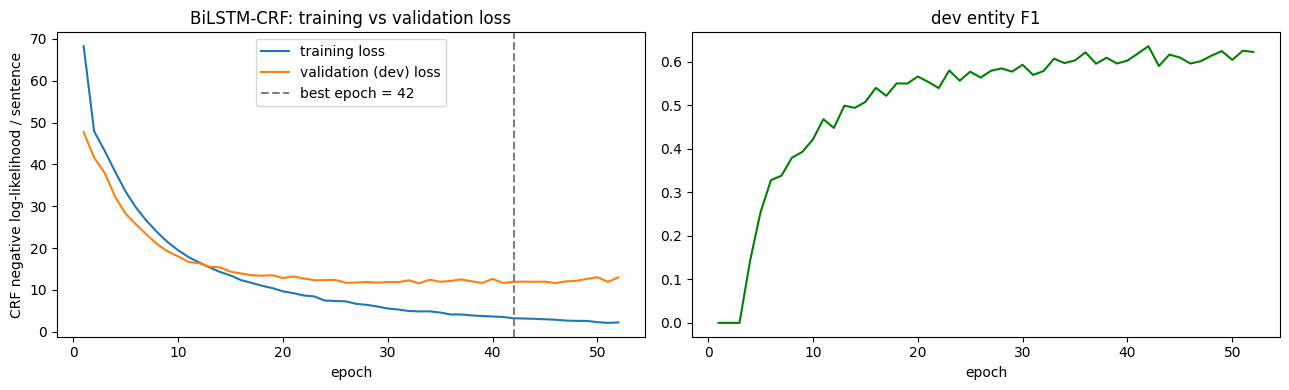

BiLSTM-CRF test P=0.6317 R=0.6278 F1=0.6297
                 precision    recall  f1-score   support

academicjournal     0.0000    0.0000    0.0000         1
      algorithm     0.5550    0.6480    0.5979       179
     conference     0.6224    0.7093    0.6630        86
        country     0.8298    0.8864    0.8571        44
          event     0.0000    0.0000    0.0000         1
          field     0.8421    0.7805    0.8101       205
       location     0.5435    0.6410    0.5882        39
        metrics     0.6587    0.7173    0.6867       191
           misc     0.3219    0.2527    0.2831       186
   organisation     0.6422    0.4730    0.5447       148
         person     0.6275    0.4706    0.5378        68
        product     0.5116    0.5556    0.5327       198
    programlang     0.8958    0.7167    0.7963        60
     researcher     0.6400    0.9114    0.7520       158
           task     0.7273    0.5845    0.6481       219
     university     0.7812    0.8929    0.8

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(lstm_hist.epoch, lstm_hist.train_loss, label="training loss")
ax[0].plot(lstm_hist.epoch, lstm_hist.val_loss, label="validation (dev) loss")
ax[0].axvline(BEST_LSTM_EPOCH, ls="--", c="grey", label=f"best epoch = {BEST_LSTM_EPOCH}")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("CRF negative log-likelihood / sentence"); ax[0].legend()
ax[0].set_title("BiLSTM-CRF: training vs validation loss")
ax[1].plot(lstm_hist.epoch, lstm_hist.val_f1, c="green"); ax[1].set_title("dev entity F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/bilstm_loss.png", dpi=120); plt.show()

t0 = time.perf_counter()
y_pred_lstm = lstm_predict(lstm_model, test_data)
TIMINGS["BiLSTM-CRF"] = {"train_s": lstm_train_s, "infer_ms_per_sent": 1000 * (time.perf_counter() - t0) / len(test_data)}
print(f"BiLSTM-CRF test P={precision_score(y_test, y_pred_lstm):.4f} R={recall_score(y_test, y_pred_lstm):.4f} "
      f"F1={f1_score(y_test, y_pred_lstm):.4f}")
print(classification_report(y_test, y_pred_lstm, digits=4, zero_division=0))

**Architecture choices**

* **Word embeddings:** pre‑trained GloVe 6B (100‑d, lower‑cased; digits normalised to `0`), fine‑tuned during
  training. Words absent from GloVe get a random vector; the vocabulary includes all training words plus any GloVe word
  that occurs in the corpus (only the unsupervised vectors are used, never test labels).
* **Character CNN** (30‑d chars, 50 filters, width 3, max‑pool): GloVe is lower‑cased, so the char CNN restores case
  and morphology (`TensorFlow`, `ResNet`, `‑ing`), and handles OOV technical terms.
* **BiLSTM** (2 × 100 hidden) reads the whole sentence in both directions; dropout 0.5 because the data is tiny.
* **CRF output layer** models tag transitions (e.g. forbids `O → I‑task`), giving valid, consistent spans – the same
  advantage the classical CRF has, on top of learned features.
* **Training:** Adam (lr 1e‑3), batch 16, gradient clipping 5. Phase 1 trains on the fit split with early stopping on
  dev F1 (curves above); phase 2 refits on all 450 sentences for the selected number of epochs.

**Results and comparison with the CRF** (full test split)

* **GloVe works as intended:** 400 k vectors loaded, 4,469 of the 4,752 vocabulary words found, and 97.5 % of test
  tokens are covered – so most words the model never saw labelled still get a meaningful vector.
* **Loss curves:** training and validation loss fall together for ~12 epochs; after ~25 epochs the validation loss
  flattens (~12) while the training loss keeps dropping towards 2 – the classic over‑fitting gap on a 405‑sentence
  training set. Dev F1 keeps creeping up slowly and peaks at **0.636 at epoch 42**, which is why we select the epoch on
  dev F1 (the metric we care about) and refit for 42 epochs on all 450 sentences.
* **BiLSTM‑CRF: P 0.632 / R 0.628 / F1 0.630 vs CRF 0.581 (+0.049).** The gain is mostly **recall**
  (0.551 → 0.628) while precision rises less (0.613 → 0.632): pre‑trained embeddings let the model recognise
  entities whose words never occurred in training, which the CRF’s sparse lexical features cannot.
* **Biggest per‑type gains:** `person` 0.154 → 0.538, `country` 0.571 → 0.857, `university` 0.646 → 0.833,
  `programlang` 0.696 → 0.796, `researcher` 0.679 → 0.752, `organisation` 0.483 → 0.545 – types whose members
  (names, places, languages) are well represented in Wikipedia‑trained GloVe.
* **Still weak:** `misc` (0.283) – a heterogeneous type with no shared meaning, so embeddings do not help much;
  `metrics` is the only frequent type that got worse (0.716 → 0.687), where the CRF’s explicit context features
  (*“… error **rate**”*) were already very effective.


## Part D – Transformer fine-tuning (2.0)

Fine-tune a BERT-family model for token classification (suggested model in your PS brief).
**Subword-to-word label alignment is mandatory and must be explained.** A helper is given below; you may adapt it.

In [17]:
from transformers import AutoTokenizer

MODEL_NAME = "allenai/scibert_scivocab_cased"   # domain-pretrained on 1.14M scientific papers (suggested in the PS3 brief)
# The hub copy of scibert_scivocab_cased has no tokenizer config, so the tokenizer would default to
# do_lower_case=True and silently lower-case the input of a CASED model -> force it off and verify.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, do_lower_case=False)
print("case preserved:", tokenizer.tokenize("TensorFlow and Geoffrey Hinton"))

def tokenize_and_align(tokens, word_labels, label2id):
    """Label only the first sub-token of each word; other sub-tokens and special tokens get -100
    so the loss ignores them."""
    enc = tokenizer(tokens, is_split_into_words=True, truncation=True)
    labels, prev = [], None
    for wid in enc.word_ids():
        if wid is None:
            labels.append(-100)
        elif wid != prev:
            labels.append(label2id[word_labels[wid]])
        else:
            labels.append(-100)
        prev = wid
    enc["labels"] = labels
    return enc

# Show the alignment on one example sentence (from the template) ...
ex_tokens = ["Aspirin", "caused", "gastrointestinal", "bleeding", "."]
ex_labels = ["B-DRUG", "O", "B-EFFECT", "I-EFFECT", "O"]
ex_map = {l: i for i, l in enumerate(sorted(set(ex_labels)))}
ex = tokenize_and_align(ex_tokens, ex_labels, ex_map)
print(list(zip(tokenizer.convert_ids_to_tokens(ex["input_ids"]), ex["labels"])))

# ... and on a real CrossRE-AI sentence, as a table: sub-token | word index | word | label used in the loss
label2id = {t: i for i, t in enumerate(tag_list)}; id2label = {i: t for t, i in label2id.items()}
d = train_data[0]
enc = tokenize_and_align(d["tokens"], d["tags"], label2id)
wids = enc.word_ids()
align = pd.DataFrame({"sub-token": tokenizer.convert_ids_to_tokens(enc["input_ids"]),
                      "word_id": pd.Series(wids, dtype=object), "label id": enc["labels"]})
align["word"] = [d["tokens"][w] if w is not None else "" for w in wids]
align["label (loss target)"] = [id2label[l] if l != -100 else "-100 (ignored)" for l in align["label id"]]
display(align.head(30))
print(f"{len(d['tokens'])} words -> {len(enc['input_ids'])} sub-tokens")

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/222k [00:00<?, ?B/s]

case preserved: ['Ten', '##sor', '##Flow', 'and', 'Ge', '##off', '##rey', 'Hin', '##ton']
[('[CLS]', -100), ('Asp', 0), ('##iri', -100), ('##n', -100), ('caused', 3), ('gastro', 1), ('##intestinal', -100), ('bleeding', 2), ('.', 3), ('[SEP]', -100)]


,sub-token,word_id,label id,word,label (loss target)
0,[CLS],None,-100,,-100 (ignored)
1,Pop,0,0,Popular,O
2,##ular,0,-100,Popular,-100 (ignored)
3,approaches,1,0,approaches,O
4,of,2,0,of,O
5,opinion,3,11,opinion-based,B-product
6,-,3,-100,opinion-based,-100 (ignored)
7,based,3,-100,opinion-based,-100 (ignored)
8,recommend,4,26,recommender,I-product
9,##er,4,-100,recommender,-100 (ignored)


64 words -> 94 sub-tokens


In [18]:
from transformers import (AutoModelForTokenClassification, DataCollatorForTokenClassification,
                          TrainingArguments, Trainer, set_seed)
from datasets import Dataset

lens = [len(tokenizer(d["tokens"], is_split_into_words=True)["input_ids"]) for d in train_data + test_data]
print(f"sub-tokens per sentence: mean {np.mean(lens):.1f}, max {max(lens)} (no truncation at 512)")

def to_hf(data):
    rows = [dict(tokenize_and_align(d["tokens"], d["tags"], label2id)) for d in data]
    return Dataset.from_list(rows)

def word_level_predict(model, data, bs=32):
    """Run the model and convert sub-token predictions back to ONE tag per original word (first sub-token)."""
    model.eval(); out = []
    for i in range(0, len(data), bs):
        batch = data[i:i + bs]
        enc = tokenizer([d["tokens"] for d in batch], is_split_into_words=True, truncation=True,
                        padding=True, return_tensors="pt").to(model.device)
        with torch.no_grad():
            pred = model(**enc).logits.argmax(-1).cpu().numpy()
        for b, d in enumerate(batch):
            tags, prev = ["O"] * len(d["tokens"]), None
            for k, wid in enumerate(enc.word_ids(b)):
                if wid is not None and wid != prev:
                    tags[wid] = id2label[int(pred[b, k])]
                prev = wid
            out.append(tags)
    return out

def make_args(out, epochs, lr, eval_each_epoch):
    # Build TrainingArguments that work on transformers v4 and v5 (argument names changed between versions).
    import inspect
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw = dict(output_dir=out, learning_rate=lr, num_train_epochs=epochs, per_device_train_batch_size=16,
              per_device_eval_batch_size=32, weight_decay=0.01, lr_scheduler_type="linear",
              logging_strategy="epoch", save_strategy="no", report_to="none", seed=SEED, data_seed=SEED,
              fp16=torch.cuda.is_available(), disable_tqdm=True)
    strategy = "epoch" if eval_each_epoch else "no"
    kw["eval_strategy" if "eval_strategy" in params else "evaluation_strategy"] = strategy
    if "warmup_ratio" in params:
        kw["warmup_ratio"] = 0.1                      # v4
    else:
        kw["warmup_steps"] = 0.1                      # v5: a float < 1 is a ratio of total steps
    return TrainingArguments(**kw)

class DevF1Callback(transformers.TrainerCallback):
    """After every epoch: word-level seqeval F1 on the dev split (so the curve uses the same metric as the report)."""
    def __init__(self, dev):
        self.dev, self.f1 = dev, []
    def on_epoch_end(self, args, state, control, model=None, **kw):
        self.f1.append(f1_score([d["tags"] for d in self.dev], word_level_predict(model, self.dev)))

def fine_tune(train_set, epochs, dev=None, lr=5e-5):
    set_seed(SEED)
    model = AutoModelForTokenClassification.from_pretrained(MODEL_NAME, num_labels=len(label2id),
                                                            id2label=id2label, label2id=label2id).to(DEVICE)
    cb = DevF1Callback(dev) if dev is not None else None
    trainer = Trainer(model=model, args=make_args("bert_ner", epochs, lr, dev is not None),
                      train_dataset=to_hf(train_set), eval_dataset=to_hf(dev) if dev is not None else None,
                      data_collator=DataCollatorForTokenClassification(tokenizer), callbacks=[cb] if cb else None)
    trainer.train()
    return model, trainer, cb

BERT_EPOCHS, BERT_LR = 20, 5e-5
# Phase 1: fit split, evaluate on dev every epoch -> learning curves + best epoch
bert_sel, bert_trainer_sel, bert_cb = fine_tune(fit_set, BERT_EPOCHS, dev=dev_set, lr=BERT_LR)
logs = pd.DataFrame(bert_trainer_sel.state.log_history)
bert_hist = pd.DataFrame({"epoch": range(1, len(bert_cb.f1) + 1),
                          "train_loss": logs.dropna(subset=["loss"])["loss"].values[:len(bert_cb.f1)],
                          "val_loss": logs.dropna(subset=["eval_loss"])["eval_loss"].values[:len(bert_cb.f1)],
                          "val_f1": bert_cb.f1})
BEST_BERT_EPOCH = int(bert_hist.loc[bert_hist.val_f1.idxmax(), "epoch"])
print(f"best dev F1 = {bert_hist.val_f1.max():.4f} at epoch {BEST_BERT_EPOCH}")
del bert_sel, bert_trainer_sel; torch.cuda.empty_cache()

sub-tokens per sentence: mean 39.3, max 106 (no truncation at 512)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  442MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: allenai/scibert_scivocab_cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	ca

model.safetensors: reconstructing file:   0%|          |  0.00B /  442MB            

model.safetensors: downloading bytes:           |  0.00B            

{'loss': '2.384', 'grad_norm': '6.256', 'learning_rate': '2.404e-05', 'epoch': '1'}
{'eval_loss': '1.359', 'eval_runtime': '0.0943', 'eval_samples_per_second': '477.2', 'eval_steps_per_second': '21.21', 'epoch': '1'}
{'loss': '1.099', 'grad_norm': '3.675', 'learning_rate': '4.904e-05', 'epoch': '2'}
{'eval_loss': '0.6543', 'eval_runtime': '0.0563', 'eval_samples_per_second': '799', 'eval_steps_per_second': '35.51', 'epoch': '2'}
{'loss': '0.501', 'grad_norm': '2.571', 'learning_rate': '4.733e-05', 'epoch': '3'}
{'eval_loss': '0.4489', 'eval_runtime': '0.0563', 'eval_samples_per_second': '799.7', 'eval_steps_per_second': '35.54', 'epoch': '3'}
{'loss': '0.2591', 'grad_norm': '3.891', 'learning_rate': '4.455e-05', 'epoch': '4'}
{'eval_loss': '0.3906', 'eval_runtime': '0.0647', 'eval_samples_per_second': '695.7', 'eval_steps_per_second': '30.92', 'epoch': '4'}
{'loss': '0.1471', 'grad_norm': '4.727', 'learning_rate': '4.177e-05', 'epoch': '5'}
{'eval_loss': '0.4076', 'eval_runtime': '0.06

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: allenai/scibert_scivocab_cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	ca

{'loss': '2.226', 'grad_norm': '8.155', 'learning_rate': '2.979e-05', 'epoch': '1'}
{'loss': '0.8828', 'grad_norm': '5.207', 'learning_rate': '4.88e-05', 'epoch': '2'}
{'loss': '0.3891', 'grad_norm': '3.966', 'learning_rate': '4.532e-05', 'epoch': '3'}
{'loss': '0.2207', 'grad_norm': '3.043', 'learning_rate': '4.185e-05', 'epoch': '4'}
{'loss': '0.1163', 'grad_norm': '5.228', 'learning_rate': '3.837e-05', 'epoch': '5'}
{'loss': '0.06734', 'grad_norm': '0.5285', 'learning_rate': '3.489e-05', 'epoch': '6'}
{'loss': '0.04346', 'grad_norm': '2.256', 'learning_rate': '3.141e-05', 'epoch': '7'}
{'loss': '0.03201', 'grad_norm': '13.8', 'learning_rate': '2.794e-05', 'epoch': '8'}
{'loss': '0.01974', 'grad_norm': '0.1952', 'learning_rate': '2.446e-05', 'epoch': '9'}
{'loss': '0.01408', 'grad_norm': '0.5599', 'learning_rate': '2.098e-05', 'epoch': '10'}
{'loss': '0.008995', 'grad_norm': '0.2536', 'learning_rate': '1.751e-05', 'epoch': '11'}
{'loss': '0.007857', 'grad_norm': '0.04794', 'learning_

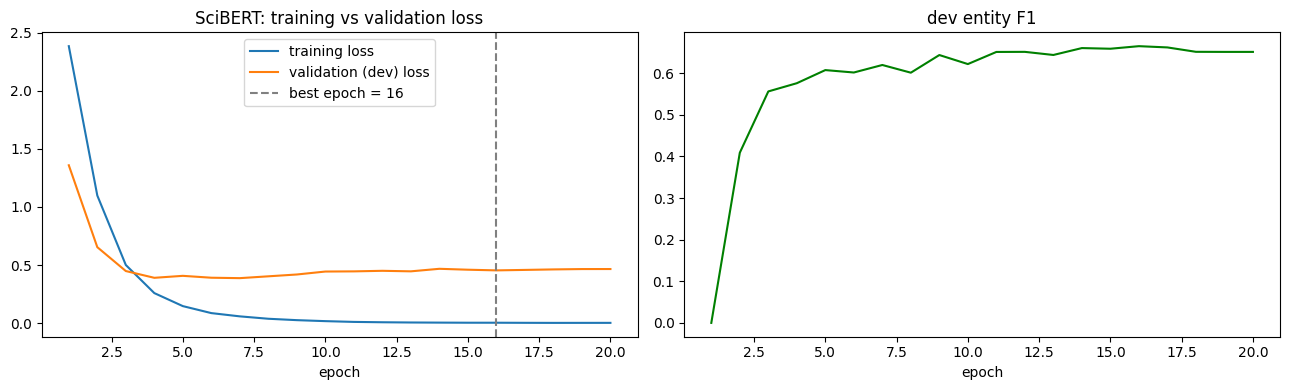

SciBERT test P=0.7027 R=0.7648 F1=0.7324  (trained 39s)
                 precision    recall  f1-score   support

academicjournal     0.0000    0.0000    0.0000         1
      algorithm     0.7841    0.7709    0.7775       179
     conference     0.7812    0.8721    0.8242        86
        country     0.8140    0.7955    0.8046        44
          event     0.0000    0.0000    0.0000         1
          field     0.8233    0.8634    0.8429       205
       location     0.7179    0.7179    0.7179        39
        metrics     0.8213    0.8901    0.8543       191
           misc     0.2780    0.3871    0.3236       186
   organisation     0.6939    0.6892    0.6915       148
         person     0.8226    0.7500    0.7846        68
        product     0.6380    0.7121    0.6730       198
    programlang     0.8525    0.8667    0.8595        60
     researcher     0.8728    0.9557    0.9124       158
           task     0.7083    0.7763    0.7407       219
     university     0.7419    0

In [19]:
# Phase 2: refit on ALL train+val for the selected number of epochs, evaluate on the full test split
t0 = time.perf_counter()
bert_model, _, _ = fine_tune(train_data, BEST_BERT_EPOCH, lr=BERT_LR)
bert_train_s = time.perf_counter() - t0
t0 = time.perf_counter()
y_pred_bert = word_level_predict(bert_model, test_data)          # word level, ready for seqeval
TIMINGS["SciBERT"] = {"train_s": bert_train_s, "infer_ms_per_sent": 1000 * (time.perf_counter() - t0) / len(test_data)}

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(bert_hist.epoch, bert_hist.train_loss, label="training loss")
ax[0].plot(bert_hist.epoch, bert_hist.val_loss, label="validation (dev) loss")
ax[0].axvline(BEST_BERT_EPOCH, ls="--", c="grey", label=f"best epoch = {BEST_BERT_EPOCH}"); ax[0].legend()
ax[0].set_title("SciBERT: training vs validation loss"); ax[0].set_xlabel("epoch")
ax[1].plot(bert_hist.epoch, bert_hist.val_f1, c="green"); ax[1].set_title("dev entity F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/scibert_loss.png", dpi=120); plt.show()

print(f"SciBERT test P={precision_score(y_test, y_pred_bert):.4f} R={recall_score(y_test, y_pred_bert):.4f} "
      f"F1={f1_score(y_test, y_pred_bert):.4f}  (trained {bert_train_s:.0f}s)")
print(classification_report(y_test, y_pred_bert, digits=4, zero_division=0))

**Sub‑word to word label alignment.** SciBERT splits words into WordPiece sub‑tokens from its scientific vocabulary
(e.g. a rare name or term may become `Bayes`, `##ian` …) and adds `[CLS]` / `[SEP]`. Labels exist per **word**, so we use
`word_ids()` from the fast tokenizer to map every sub‑token back to its word:

1. `[CLS]`, `[SEP]` and padding (`word_id = None`) → label **‑100**, which PyTorch’s cross‑entropy ignores.
2. The **first** sub‑token of each word gets the word’s BIO label.
3. Every **following** sub‑token of the same word → **‑100**, so each word contributes exactly one loss term and long
   words are not over‑weighted.

At prediction time we invert the same mapping: take the predicted tag of the first sub‑token of each word, giving one tag
per original CrossRE token, and score these word‑level tags with seqeval – so the transformer is evaluated on exactly the
same units as the CRF and BiLSTM. (Alternative: label all sub‑tokens, using `I‑X` for continuation pieces, and
aggregate at inference; first‑sub‑token is the standard BERT‑NER recipe.) The alignment table above shows this on a real
training sentence.

**Training settings.** `scibert_scivocab_cased` (cased because capitalisation matters for names/products – the tokenizer
is loaded with `do_lower_case=False`, otherwise the hub default would lower‑case the input), AdamW
lr 5e‑5, linear schedule with 10 % warm‑up, weight decay 0.01, batch 16, fp16 on GPU, seed 42. The number of epochs is
selected on the dev split (curves above), then the model is refit on all 450 sentences.

**Results** (full test split)

* **Learning curves:** the dev loss reaches its minimum after ~4–7 epochs and then drifts slightly upwards while the
  training loss goes to ≈0, yet dev F1 keeps improving slowly and peaks at **0.665 at epoch 16** – the model becomes
  more confident on wrong tokens (higher loss) while getting more entities exactly right. We therefore select on dev
  F1, not dev loss, and refit for 16 epochs on all 450 sentences (39 s on the T4).
* **SciBERT: P 0.703 / R 0.765 / F1 0.732** – the best NER model: **+0.103 over the BiLSTM‑CRF (0.630)** and
  **+0.152 over the CRF (0.581)**, with the highest precision *and* recall. Macro‑F1 rises to 0.662 (BiLSTM 0.571),
  i.e. the gain is spread across types, not just the frequent ones.
* **Largest gains over the BiLSTM‑CRF:** `person` 0.538 → 0.785, `researcher` 0.752 → 0.912, `algorithm`
  0.598 → 0.778, `metrics` 0.687 → 0.854, `conference` 0.663 → 0.824, `organisation` 0.545 → 0.692, `product`
  0.533 → 0.673, `location` 0.588 → 0.718. Contextual, domain‑pre‑trained representations disambiguate exactly the
  cases that depend on context (*a person who “proposed” a method is a researcher*) and technical vocabulary.
* **Remaining weaknesses:** `misc` stays low (0.324) for every model – it has no consistent meaning. Recall exceeds
  precision (0.765 vs 0.703): SciBERT tends to over‑extend spans or tag generic phrases (see Part G errors).
  `academicjournal` (2 training examples) and the test‑only `event` remain at 0. `country` (0.805) and `university`
  (0.780) are the only types where the BiLSTM‑CRF (0.857 / 0.833) is better.


## Part E – LLM-based NER (1.5)

Run **zero-shot** and **few-shot (3–5 examples)** prompting on a fixed sample of at least 100 test sentences.
The LLM must return JSON. Map it back to token spans and score with seqeval.
Save prompts and raw responses to CSV, show the first 5, and count unparseable responses.

A simulated or hard-coded stand-in presented as an LLM scores zero. If you have no API access, use a small local open model and name it.

In [20]:
SAMPLE_SIZE = 100
rng = random.Random(SEED)
sample_idx = sorted(rng.sample(range(len(test_tokens)), SAMPLE_SIZE))

LLM_NAME = "Qwen/Qwen2.5-3B-Instruct"   # real local open-weights instruction model (HF transformers, fp16 on a T4)
print("sample size:", len(sample_idx), "| first ids:", sample_idx[:10])
print("entities in sample:", sum(len(test_data[i]["spans"]) for i in sample_idx))

sample size: 100 | first ids: [3, 12, 13, 15, 16, 22, 23, 35, 36, 40]
entities in sample: 422


In [21]:
TYPE_SYNONYMS = {"organization": "organisation", "org": "organisation", "programming language": "programlang",
                 "programming_language": "programlang", "programminglanguage": "programlang", "metric": "metrics",
                 "journal": "academicjournal", "academic journal": "academicjournal", "people": "person",
                 "researchers": "researcher", "algorithms": "algorithm", "tasks": "task", "fields": "field",
                 "products": "product", "universities": "university", "conferences": "conference"}

def _norm(s):
    return re.sub(r"\s+", "", s.lower())

def parse_llm_json(raw_response):
    """Return (list_of_items, status) with status in {ok, salvaged, failed}."""
    txt = re.sub(r"```(?:json)?", "", raw_response)
    match = re.search(r"\[.*\]", txt, re.S)
    if match:
        try:
            items = json.loads(match.group(0))
            if isinstance(items, list):
                return [x for x in items if isinstance(x, dict)], "ok"
        except Exception:
            pass
    # Salvage complete {...} objects (e.g. output cut off by max_new_tokens). Still JSON, but counted separately.
    items = []
    for m in re.finditer(r"\{[^{}]*\}", txt):
        try:
            items.append(json.loads(m.group(0)))
        except Exception:
            pass
    return (items, "salvaged") if items else ([], "failed")

def llm_json_to_bio(tokens, raw_response, entity_types):
    """Parse the LLM's JSON list of {"text":..., "type":...} and map each entity to the first
    matching token span not already tagged. Returns (bio_tags, parsed_ok).
    Matching ignores whitespace, so "opinion-based recommender system" or "X.Y. Feng" match however the
    LLM spaces them; longer entities are placed first so they are not blocked by their own sub-strings."""
    tags = ["O"] * len(tokens)
    items, status = parse_llm_json(raw_response)
    if status == "failed":
        return tags, False
    lowered = [_norm(t) for t in tokens]
    cands = []
    for item in items:
        etype = str(item.get("type", "")).strip().lower()
        etype = TYPE_SYNONYMS.get(etype, etype)
        ent = _norm(str(item.get("text", "")))
        if etype in entity_types and ent:
            cands.append((ent, etype))
    for ent, etype in sorted(cands, key=lambda c: -len(c[0])):
        for s in range(len(tokens)):
            acc, e = "", s
            while e < len(tokens) and len(acc) < len(ent):
                acc += lowered[e]; e += 1
            if acc == ent and all(t == "O" for t in tags[s:e]):
                tags[s] = f"B-{etype}"
                for k in range(s + 1, e):
                    tags[k] = f"I-{etype}"
                break
    return tags, status == "ok"

# Unit test of the mapper on a known sentence (this is NOT an LLM output, just a check of the parser)
toks = ["We", "use", "opinion-based", "recommender", "system", "and", "X.Y.", "Feng", "'s", "CNN", "."]
print(llm_json_to_bio(toks, 'Sure! ```json\n[{"text": "opinion-based recommender system", "type": "product"}, '
                            '{"text": "X.Y. Feng", "type": "researcher"}, {"text": "CNN", "type": "Algorithm"}]```',
                      ENTITY_TYPES))
print(llm_json_to_bio(toks, "I could not find entities", ENTITY_TYPES))

(['O', 'O', 'B-product', 'I-product', 'I-product', 'O', 'B-researcher', 'I-researcher', 'O', 'B-algorithm', 'O'], True)
(['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O'], False)


In [22]:
TYPE_DEFINITIONS = {
    "algorithm": "a specific AI/ML method, model or algorithm (e.g. support vector machine, CNN, backpropagation)",
    "task": "a problem that AI methods solve (e.g. machine translation, speech recognition, classification)",
    "field": "a research area or discipline (e.g. machine learning, computer vision, natural language processing)",
    "product": "a concrete software system, tool, library, robot or dataset (e.g. TensorFlow, WordNet, Watson)",
    "researcher": "a person who is a scientist/researcher in AI",
    "person": "a person who is NOT described as a researcher",
    "metrics": "an evaluation measure (e.g. accuracy, F1 score, BLEU, mean squared error)",
    "programlang": "a programming language (e.g. Python, Lisp, MATLAB)",
    "conference": "a conference or workshop (e.g. NeurIPS, ACL, AAAI)",
    "university": "a university or academic institute",
    "organisation": "a company or non-academic organisation (e.g. Google, DARPA, IEEE)",
    "country": "a country",
    "location": "a city, region or other place that is not a country",
    "academicjournal": "an academic journal",
    "misc": "any other AI-related named entity (e.g. awards, theories, concepts, languages)",
}
assert set(ENTITY_TYPES) <= set(TYPE_DEFINITIONS), set(ENTITY_TYPES) - set(TYPE_DEFINITIONS)

SYSTEM_PROMPT = (
    "You are an information-extraction system for AI research text. Extract every named entity of these types:\n"
    + "\n".join(f"- {t}: {TYPE_DEFINITIONS[t]}" for t in ENTITY_TYPES)
    + "\nCopy each entity's text exactly as it appears in the sentence. Do not add entities that are not in the sentence."
    "\nReturn ONLY a JSON array of objects with keys \"text\" and \"type\", e.g. "
    "[{\"text\": \"support vector machine\", \"type\": \"algorithm\"}]. Return [] if there are no entities.")

def gold_json(d):
    return json.dumps([{"text": " ".join(d["tokens"][s:e + 1]), "type": t} for s, e, t in d["spans"]], ensure_ascii=False)

def pick_few_shot(k=5, max_len=35):
    """Greedy, deterministic choice of k short train sentences that together cover as many entity types as possible."""
    pool = [d for d in train_data if len(d["tokens"]) <= max_len and d["spans"]]
    chosen, covered = [], set()
    for _ in range(k):
        best = max(pool, key=lambda d: (len({t for *_, t in d["spans"]} - covered), len(d["spans"]), d["doc_key"]))
        chosen.append(best); covered |= {t for *_, t in best["spans"]}; pool.remove(best)
    return chosen, covered

FEW_SHOT, fs_cov = pick_few_shot(5)
print("few-shot examples:", [d["doc_key"] for d in FEW_SHOT], f"cover {len(fs_cov)}/{len(ENTITY_TYPES)} types")

def build_messages(tokens, setting):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    if setting == "few-shot":
        for d in FEW_SHOT:
            msgs.append({"role": "user", "content": "Sentence: " + " ".join(d["tokens"])})
            msgs.append({"role": "assistant", "content": gold_json(d)})
    msgs.append({"role": "user", "content": "Sentence: " + " ".join(tokens)})
    return msgs

print(json.dumps(build_messages(test_tokens[sample_idx[0]], "zero-shot"), indent=1)[:1500])

few-shot examples: ['ai-train-54', 'ai-dev-32', 'ai-dev-184', 'ai-dev-76', 'ai-dev-71'] cover 15/15 types
[
 {
  "role": "system",
  "content": "You are an information-extraction system for AI research text. Extract every named entity of these types:\n- academicjournal: an academic journal\n- algorithm: a specific AI/ML method, model or algorithm (e.g. support vector machine, CNN, backpropagation)\n- conference: a conference or workshop (e.g. NeurIPS, ACL, AAAI)\n- country: a country\n- field: a research area or discipline (e.g. machine learning, computer vision, natural language processing)\n- location: a city, region or other place that is not a country\n- metrics: an evaluation measure (e.g. accuracy, F1 score, BLEU, mean squared error)\n- misc: any other AI-related named entity (e.g. awards, theories, concepts, languages)\n- organisation: a company or non-academic organisation (e.g. Google, DARPA, IEEE)\n- person: a person who is NOT described as a researcher\n- product: a concrete

In [23]:
from transformers import AutoModelForCausalLM

for _m in ["bert_model", "lstm_sel"]:              # free GPU memory before loading the LLM
    if _m in globals():
        globals()[_m].cpu()
torch.cuda.empty_cache()

_dtype = torch.float16 if torch.cuda.is_available() else torch.float32
_kw = {"dtype": _dtype} if int(transformers.__version__.split(".")[0]) >= 5 else {"torch_dtype": _dtype}
llm_tok = AutoTokenizer.from_pretrained(LLM_NAME, padding_side="left")
if llm_tok.pad_token is None:
    llm_tok.pad_token = llm_tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, **_kw).to(DEVICE).eval()
print(f"{LLM_NAME}: {sum(p.numel() for p in llm.parameters())/1e9:.2f}B parameters on {DEVICE}")

def run_llm(setting, idx, bs=8, max_new_tokens=512):
    records = []
    for i in range(0, len(idx), bs):
        chunk = idx[i:i + bs]
        prompts = [llm_tok.apply_chat_template(build_messages(test_tokens[j], setting), tokenize=False,
                                               add_generation_prompt=True) for j in chunk]
        enc = llm_tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
        t0 = time.perf_counter()
        with torch.no_grad():
            out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=llm_tok.pad_token_id)
        dt = (time.perf_counter() - t0) / len(chunk)
        for b, j in enumerate(chunk):
            gen = out[b, enc["input_ids"].shape[1]:]
            raw_resp = llm_tok.decode(gen, skip_special_tokens=True)
            pred, ok = llm_json_to_bio(test_tokens[j], raw_resp, ENTITY_TYPES)
            records.append({"setting": setting, "test_idx": j, "doc_key": test_data[j]["doc_key"],
                            "prompt": prompts[b], "raw_response": raw_resp, "parse_status": parse_llm_json(raw_resp)[1],
                            "parsed_ok": ok, "n_pred_entities": len(bio_to_spans(pred)), "pred_tags": " ".join(pred),
                            "prompt_tokens": int(enc["attention_mask"][b].sum()), "output_tokens": int((gen != llm_tok.pad_token_id).sum()),
                            "latency_s": round(dt, 3)})
    return records

llm_records = []
for setting in ["zero-shot", "few-shot"]:
    t0 = time.perf_counter()
    llm_records += run_llm(setting, sample_idx)
    print(f"{setting}: {time.perf_counter() - t0:.0f}s for {len(sample_idx)} sentences")

llm_df = pd.DataFrame(llm_records)
llm_df.to_csv(f"{OUT_DIR}/llm_ner_outputs.csv", index=False)
print("saved", f"{OUT_DIR}/llm_ner_outputs.csv", llm_df.shape)
display(llm_df[["setting", "doc_key", "raw_response", "parse_status", "n_pred_entities", "latency_s"]].head(5))
print("Prompt of the first row:\n", llm_df.prompt.iloc[0][-700:])

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

... (3 outputs left out)

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-3B-Instruct: 3.09B parameters on cuda
zero-shot: 87s for 100 sentences
few-shot: 162s for 100 sentences
saved outputs/llm_ner_outputs.csv (200, 12)


,setting,doc_key,raw_response,parse_status,n_pred_entities,latency_s
0,zero-shot,ai-test-4,"[\n {""text"": ""neural network"", ""type"": ""algorithm""},\n {""text"": ""Support vector machine"", ""type"": ""algorithm""}\n]",ok,2,0.647
1,zero-shot,ai-test-13,[],ok,0,0.647
2,zero-shot,ai-test-14,"[\n {""text"": ""Alexa"", ""type"": ""organisation""},\n {""text"": ""Siri"", ""type"": ""organisation""}\n]",ok,2,0.647
3,zero-shot,ai-test-16,[],ok,0,0.647
4,zero-shot,ai-test-17,"[{""text"": ""Engelberger"", ""type"": ""person""}, {""text"": ""Unimate"", ""type"": ""product""}, {""text"": ""Robot Hall of Fame"", ""...",ok,3,0.647


Prompt of the first row:
 recognition, classification)
- university: a university or academic institute
Copy each entity's text exactly as it appears in the sentence. Do not add entities that are not in the sentence.
Return ONLY a JSON array of objects with keys "text" and "type", e.g. [{"text": "support vector machine", "type": "algorithm"}]. Return [] if there are no entities.<|im_end|>
<|im_start|>user
Sentence: Unlike neural network s and Support vector machine , the AdaBoost training process selects only those features known to improve the predictive power of the model , reducing dimensionality and potentially improving execution time as irrelevant features need not be computed .<|im_end|>
<|im_start|>assistant



In [24]:
y_true_sample = [test_tags[i] for i in sample_idx]
llm_preds = {}
summary = []
for setting in ["zero-shot", "few-shot"]:
    sub = llm_df[llm_df.setting == setting].set_index("test_idx").loc[sample_idx]
    preds = [p.split(" ") for p in sub.pred_tags]
    llm_preds[setting] = preds
    counts = sub.parse_status.value_counts()
    summary.append({"setting": setting, "unparseable (failed)": int(counts.get("failed", 0)),
                    "salvaged (truncated/invalid JSON)": int(counts.get("salvaged", 0)),
                    "valid JSON": int(counts.get("ok", 0)),
                    "P": precision_score(y_true_sample, preds), "R": recall_score(y_true_sample, preds),
                    "F1": f1_score(y_true_sample, preds), "avg latency s/sent": sub.latency_s.mean(),
                    "avg prompt tokens": sub.prompt_tokens.mean(), "avg output tokens": sub.output_tokens.mean()})
    print(f"===== {setting} =====")
    print(classification_report(y_true_sample, preds, digits=4, zero_division=0))
llm0_sample, llmk_sample = llm_preds["zero-shot"], llm_preds["few-shot"]
llm_summary = pd.DataFrame(summary).set_index("setting"); display(llm_summary.round(4))
for setting in ["zero-shot", "few-shot"]:
    TIMINGS[f"LLM {setting}"] = {"train_s": 0.0,
                                 "infer_ms_per_sent": 1000 * llm_summary.loc[setting, "avg latency s/sent"]}

===== zero-shot =====
                 precision    recall  f1-score   support

academicjournal     0.0000    0.0000    0.0000         0
      algorithm     0.7273    0.3902    0.5079        41
     conference     0.8125    0.5000    0.6190        26
        country     0.9231    0.7500    0.8276        16
          field     0.8571    0.3333    0.4800        36
       location     0.8571    0.6000    0.7059        10
        metrics     0.5000    0.0930    0.1569        43
           misc     0.0000    0.0000    0.0000        45
   organisation     0.5000    0.2414    0.3256        29
         person     0.0000    0.0000    0.0000        19
        product     0.4615    0.2353    0.3117        51
    programlang     0.5000    0.1000    0.1667        10
     researcher     0.0000    0.0000    0.0000        24
           task     0.6809    0.4638    0.5517        69
     university     1.0000    0.3333    0.5000         3

      micro avg     0.6073    0.2749    0.3785       422
      m

,unparseable (failed),salvaged (truncated/invalid JSON),valid JSON,P,R,F1,avg latency s/sent,avg prompt tokens,avg output tokens
setting,,,,,,,,,
zero-shot,0,0,100,0.6073,0.2749,0.3785,0.8650,400.77,32.45
few-shot,0,0,100,0.5674,0.5284,0.5472,1.6143,1097.77,59.95


In [25]:
# What did the LLM actually return? (computed from the raw responses saved in the CSV)
llm_behaviour = []
for setting in ["zero-shot", "few-shot"]:
    sub = llm_df[llm_df.setting == setting]
    items = [it for r in sub.raw_response for it in parse_llm_json(r)[0]]
    types = Counter(TYPE_SYNONYMS.get(str(it.get("type", "")).strip().lower(), str(it.get("type", "")).strip().lower())
                    for it in items)
    off_schema = {t: n for t, n in types.items() if t not in ENTITY_TYPES}
    llm_behaviour.append({"setting": setting,
                          "sentences answered with []": int(sum(len(parse_llm_json(r)[0]) == 0 for r in sub.raw_response)),
                          "entities returned": len(items),
                          "entities kept after span matching": int(sub.n_pred_entities.sum()),
                          "gold entities in sample": sum(len(test_data[i]["spans"]) for i in sample_idx),
                          "'researcher' predicted": types.get("researcher", 0),
                          "'person' predicted": types.get("person", 0),
                          "off-schema types": sum(off_schema.values()),
                          "off-schema examples": ", ".join(sorted(off_schema)[:6])})
llm_behaviour = pd.DataFrame(llm_behaviour).set_index("setting"); display(llm_behaviour)

,sentences answered with [],entities returned,entities kept after span matching,gold entities in sample,'researcher' predicted,'person' predicted,off-schema types,off-schema examples
setting,,,,,,,,
zero-shot,49,197,191,422,0,15,2,
few-shot,8,411,393,422,12,23,11,"acronym, award, concept, model, year"


**Setup.** `Qwen/Qwen2.5-3B-Instruct` (open weights, run locally with HF `transformers` in fp16 on the Colab T4,
greedy decoding, max 512 new tokens, batch 8). The system prompt lists the 15 entity types with one‑line definitions and
demands a JSON array of `{"text", "type"}`. **Few‑shot** adds 5 training sentences (chosen greedily to cover the most
entity types; printed above) as user/assistant turns with their gold JSON. The same fixed 100‑sentence test sample
(`random.Random(42).sample`) is used for both settings and later for Part G.

**JSON → spans.** The parser strips code fences, takes the outermost `[...]`, and maps each entity’s text to the first
untagged token span whose concatenation matches (whitespace‑insensitive, longest entities first). Responses whose JSON
cannot be parsed are counted as *failed* (they contribute all‑`O` predictions, i.e. they are penalised, not dropped);
responses where only some complete objects could be recovered (usually cut off at the token limit) are counted as
*salvaged*. All prompts and raw responses are in `outputs/llm_ner_outputs.csv`.

**Zero‑shot vs few‑shot** (same 100 sentences, 422 gold entities)

* **Parsing is not the problem:** both settings returned valid JSON for **100/100** responses (0 failed, 0 salvaged) –
  the instruction‑tuned model follows the output format reliably.
* **Zero‑shot: P 0.607 / R 0.275 / F1 0.3785.** Precision is reasonable but recall is very low: the behaviour table
  shows the model answered `[]` for **49 of the 100 sentences** (it returned 197 entities for 422 gold ones), i.e. without examples it does not know how much CrossRE
  counts as an entity (generic method/task phrases such as *“information retrieval”* are entities here). It also
  **never predicts `researcher`** – it labels researchers as `person` (e.g. *Gerd Gigerenzer*, *Wolfram Burgard*), so
  both types score 0, and `misc` is never right.
* **Few‑shot (5 examples): P 0.567 / R 0.528 / F1 0.547 (+0.169).** Examples teach the annotation *granularity*:
  only 8 empty answers and 411 returned entities, recall almost doubles, and `researcher` (0.611), `person` (0.619), `organisation`
  (0.644) and `programlang` (0.706) appear. Precision drops slightly because the model now also tags non‑entities and
  sometimes invents types outside the schema (11 entities typed `acronym`, `award`, `concept`, `model`, `year` – discarded
  by the mapper). It still labels some researchers as `person` (12 `researcher` vs 23 `person` predictions). `misc` remains 0 in both settings – its meaning is defined only by the dataset’s guidelines.
* **Cost:** few‑shot prompts are ~2.7× longer (≈1,098 vs ≈401 prompt tokens) and latency rises from 0.87 s to 1.61 s
  per sentence on the T4 – two to three orders of magnitude slower than the CRF/BiLSTM/SciBERT at inference
  (ms/sentence column in the Part G table). A local
  3B model costs nothing per call and keeps client text private; a larger API model would likely score higher but
  adds per‑token cost and data‑sharing concerns.
* Even with few‑shot prompting the LLM stays **below all three supervised models** on the same sample (Part G).

## Part F – Relation extraction, light (1.5)

Candidates: all ordered pairs of gold entities in a sentence. Label = annotated relation, else `NO_RELATION`.
Cap `NO_RELATION` at twice the positive pairs in train and in test (use `SEED`).
CrossRE groups (PS3–PS7): keep the 5 most frequent relation types, map the rest to `OTHER`.

Method 1: classical baseline (e.g. logistic regression on entity types, words between, distance).
Method 2: LLM prompting **or** a fine-tuned transformer. Report macro-F1 and a confusion matrix for both.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report as cls_report, confusion_matrix, f1_score as sk_f1
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.feature_extraction import DictVectorizer

rel_counts = Counter(lab for d in train_data for lab in d["relations"].values())
TOP5 = [r for r, _ in rel_counts.most_common(5)]
print("relation frequencies in train+val (first label kept):", dict(rel_counts.most_common()))
print("TOP-5 kept:", TOP5, "| all others -> OTHER")

def build_pairs(data, seed=SEED):
    pos, neg = [], []
    for si, d in enumerate(data):
        ents = d["spans"]
        for a in ents:
            for b in ents:
                if a == b:
                    continue
                lab = d["relations"].get((a[0], a[1], b[0], b[1]))
                item = {"sent": si, "e1": a, "e2": b,
                        "label": "NO_RELATION" if lab is None else (lab if lab in TOP5 else "OTHER")}
                (neg if lab is None else pos).append(item)
    rnd = random.Random(seed)
    neg_kept = rnd.sample(neg, min(len(neg), 2 * len(pos)))          # cap NO_RELATION at 2x positives
    pairs = pos + neg_kept; rnd.shuffle(pairs)
    return pairs, len(pos), len(neg)

re_train, p_tr, n_tr = build_pairs(train_data)
re_test, p_te, n_te = build_pairs(test_data)
RE_LABELS = TOP5 + ["OTHER", "NO_RELATION"]
print(f"train: {p_tr} positive, {n_tr} negative candidates -> kept {len(re_train) - p_tr} NO_RELATION")
print(f"test : {p_te} positive, {n_te} negative candidates -> kept {len(re_test) - p_te} NO_RELATION")
display(pd.DataFrame({"train": Counter(p["label"] for p in re_train), "test": Counter(p["label"] for p in re_test)}).loc[RE_LABELS])

relation frequencies in train+val (first label kept): {'part-of': 301, 'named': 167, 'physical': 156, 'related-to': 144, 'role': 115, 'origin': 87, 'type-of': 75, 'usage': 61, 'artifact': 58, 'compare': 52, 'topic': 47, 'general-affiliation': 29, 'temporal': 26, 'win-defeat': 23, 'opposite': 10, 'cause-effect': 4, 'social': 1}
TOP-5 kept: ['part-of', 'named', 'physical', 'related-to', 'role'] | all others -> OTHER
train: 1356 positive, 9664 negative candidates -> kept 2712 NO_RELATION
test : 1127 positive, 8009 negative candidates -> kept 2254 NO_RELATION


,train,test
part-of,301,211
named,167,139
physical,156,101
related-to,144,107
role,115,87
OTHER,473,482
NO_RELATION,2712,2254


Method 1 - Logistic regression (9,505 features, 1.8s): macro-F1 = 0.5232
              precision    recall  f1-score   support

     part-of     0.4153    0.4645    0.4385       211
       named     0.6269    0.6043    0.6154       139
    physical     0.6071    0.6733    0.6385       101
  related-to     0.2609    0.2243    0.2412       107
        role     0.4598    0.4598    0.4598        87
       OTHER     0.4541    0.4315    0.4426       482
 NO_RELATION     0.8249    0.8279    0.8264      2254

    accuracy                         0.7063      3381
   macro avg     0.5213    0.5265    0.5232      3381
weighted avg     0.7046    0.7063    0.7052      3381



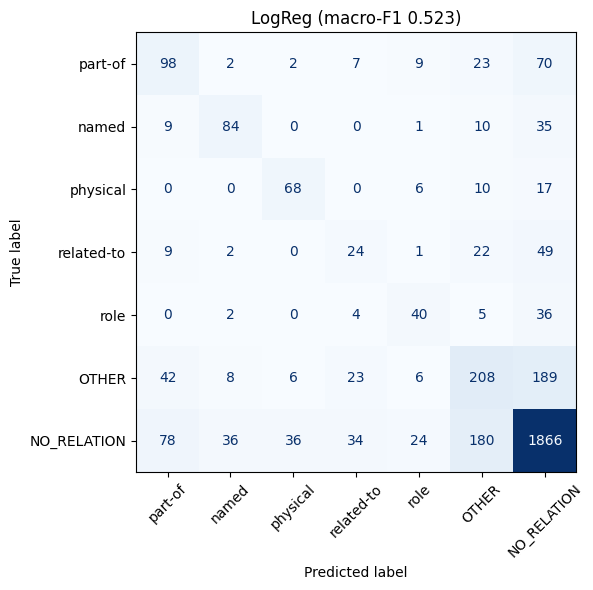

In [27]:
def pair_features(p, data):
    d = data[p["sent"]]; toks = [w.lower() for w in d["tokens"]]
    (s1, e1, t1), (s2, e2, t2) = p["e1"], p["e2"]
    left, right = (e1, s2) if s1 < s2 else (e2, s1)
    between = toks[left + 1:right]
    f = {"t1=" + t1: 1, "t2=" + t2: 1, f"pair={t1}|{t2}": 1, "e1_first": int(s1 < s2),
         "dist_bucket": str(min(len(between), 10) if len(between) < 10 else "10+"),
         "n_ents_between": sum(1 for s, e, _ in d["spans"] if s > left and e < right),
         "between_empty": int(len(between) == 0)}
    for w in between:
        f["bw=" + w] = 1
    if between:
        f["bw_first=" + between[0]] = 1; f["bw_last=" + between[-1]] = 1
    for w in toks[s1:e1 + 1]:
        f["e1w=" + w] = 1
    for w in toks[s2:e2 + 1]:
        f["e2w=" + w] = 1
    f["e1_head=" + toks[e1]] = 1; f["e2_head=" + toks[e2]] = 1
    for k in (1, 2):
        if min(s1, s2) - k >= 0:
            f[f"before-{k}=" + toks[min(s1, s2) - k]] = 1
        if max(e1, e2) + k < len(toks):
            f[f"after+{k}=" + toks[max(e1, e2) + k]] = 1
    return f

vec = DictVectorizer()
X_tr = vec.fit_transform([pair_features(p, train_data) for p in re_train])
X_te = vec.transform([pair_features(p, test_data) for p in re_test])
yr_tr = [p["label"] for p in re_train]; yr_te = [p["label"] for p in re_test]

t0 = time.perf_counter()
logreg = LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced", random_state=SEED).fit(X_tr, yr_tr)
re_lr_train_s = time.perf_counter() - t0
yr_pred_lr = logreg.predict(X_te)
re_macro_lr = sk_f1(yr_te, yr_pred_lr, labels=RE_LABELS, average="macro")
print(f"Method 1 - Logistic regression ({X_tr.shape[1]:,} features, {re_lr_train_s:.1f}s): macro-F1 = {re_macro_lr:.4f}")
print(cls_report(yr_te, yr_pred_lr, labels=RE_LABELS, digits=4, zero_division=0))

def plot_cm(y_true, y_pred, title, ax):
    cm = confusion_matrix(y_true, y_pred, labels=RE_LABELS)
    ConfusionMatrixDisplay(cm, display_labels=RE_LABELS).plot(ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(7, 6)); plot_cm(yr_te, yr_pred_lr, f"LogReg (macro-F1 {re_macro_lr:.3f})", ax)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/re_cm_logreg.png", dpi=120); plt.show()

Since 2009 , the [E1] algorithm | recurrent neural network [/E1] s and deep feedforward neural networks developed in the research group of Jürgen Schmidhuber at the Swiss AI Lab IDSIA have won several [E2] misc | international handwriting competitions [/E2] .. -> OTHER


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allenai/scibert_scivocab_cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

{'loss': '1.116', 'grad_norm': '24.39', 'learning_rate': '2.78e-05', 'epoch': '1'}
{'loss': '0.7587', 'grad_norm': '7.794', 'learning_rate': '2.224e-05', 'epoch': '2'}
{'loss': '0.5613', 'grad_norm': '11.74', 'learning_rate': '1.669e-05', 'epoch': '3'}
{'loss': '0.4395', 'grad_norm': '12.66', 'learning_rate': '1.113e-05', 'epoch': '4'}
{'loss': '0.3529', 'grad_norm': '8.05', 'learning_rate': '5.577e-06', 'epoch': '5'}
{'loss': '0.2838', 'grad_norm': '18.96', 'learning_rate': '2.179e-08', 'epoch': '6'}
{'train_runtime': '144.6', 'train_samples_per_second': '168.8', 'train_steps_per_second': '10.58', 'train_loss': '0.5853', 'epoch': '6'}
Method 2 - SciBERT + entity markers (145s): macro-F1 = 0.5300
              precision    recall  f1-score   support

     part-of     0.3696    0.4028    0.3855       211
       named     0.7222    0.7482    0.7350       139
    physical     0.6512    0.5545    0.5989       101
  related-to     0.3117    0.2243    0.2609       107
        role     0.5690

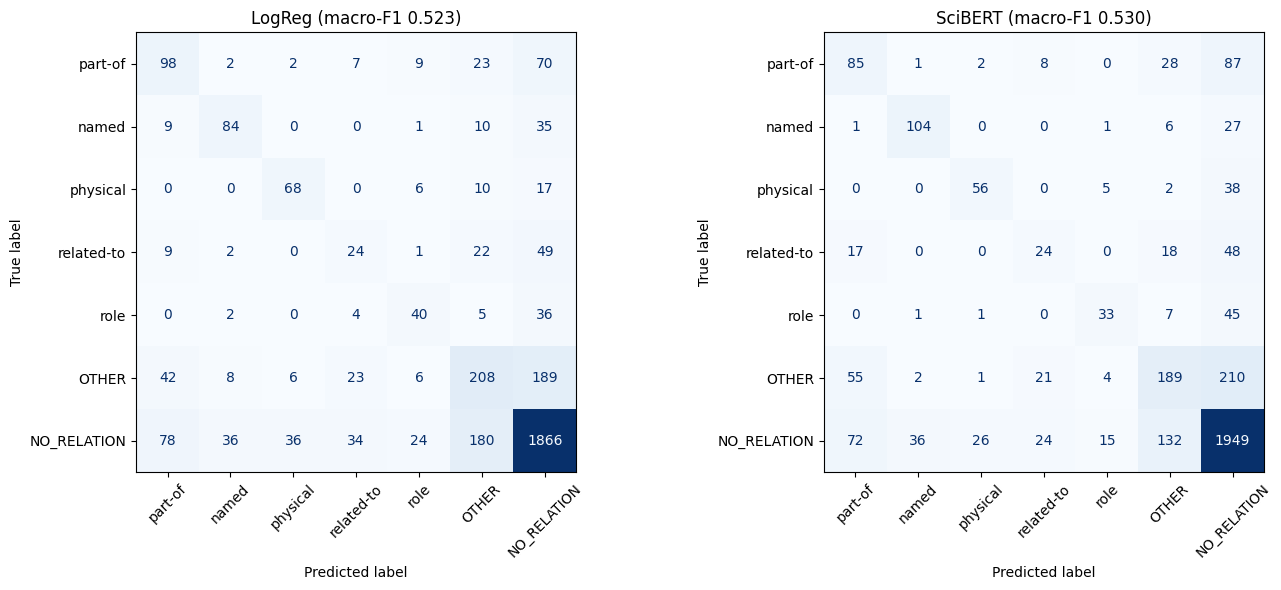

,Method,macro-F1,train time (s)
0,Logistic regression,0.5232,1.8153
1,SciBERT + entity markers,0.5300,145.1023


In [28]:
# Method 2 - fine-tuned SciBERT relation classifier with entity markers
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding

for _m in ["llm"]:                                   # free the LLM
    if _m in globals():
        del globals()[_m]
torch.cuda.empty_cache()

MARKERS = ["[E1]", "[/E1]", "[E2]", "[/E2]"]
re_tok = AutoTokenizer.from_pretrained(MODEL_NAME, do_lower_case=False)
re_tok.add_special_tokens({"additional_special_tokens": MARKERS})
rel2id = {r: i for i, r in enumerate(RE_LABELS)}; id2rel = {i: r for r, i in rel2id.items()}

def marked_text(p, data):
    """Insert typed entity markers: ... [E1] algorithm | CNN [/E1] ... [E2] task | image recognition [/E2] ..."""
    d = data[p["sent"]]; (s1, e1, t1), (s2, e2, t2) = p["e1"], p["e2"]
    out = []
    for i, w in enumerate(d["tokens"]):
        if i == s1: out += ["[E1]", t1, "|"]
        if i == s2: out += ["[E2]", t2, "|"]
        out.append(w)
        if i == e1: out.append("[/E1]")
        if i == e2: out.append("[/E2]")
    return " ".join(out)

print(marked_text(re_train[0], train_data), "->", re_train[0]["label"])

def re_dataset(pairs, data):
    enc = re_tok([marked_text(p, data) for p in pairs], truncation=True, max_length=256)
    enc["labels"] = [rel2id[p["label"]] for p in pairs]
    return Dataset.from_dict(dict(enc))

set_seed(SEED)
re_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(RE_LABELS),
                                                              id2label=id2rel, label2id=rel2id)
re_model.resize_token_embeddings(len(re_tok))
re_args = make_args("bert_re", epochs=6, lr=3e-5, eval_each_epoch=False)
re_trainer = Trainer(model=re_model.to(DEVICE), args=re_args, train_dataset=re_dataset(re_train, train_data),
                     data_collator=DataCollatorWithPadding(re_tok))
t0 = time.perf_counter(); re_trainer.train(); re_bert_train_s = time.perf_counter() - t0
logits = re_trainer.predict(re_dataset(re_test, test_data)).predictions
yr_pred_bert = [id2rel[i] for i in logits.argmax(-1)]
re_macro_bert = sk_f1(yr_te, yr_pred_bert, labels=RE_LABELS, average="macro")
print(f"Method 2 - SciBERT + entity markers ({re_bert_train_s:.0f}s): macro-F1 = {re_macro_bert:.4f}")
print(cls_report(yr_te, yr_pred_bert, labels=RE_LABELS, digits=4, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
plot_cm(yr_te, yr_pred_lr, f"LogReg (macro-F1 {re_macro_lr:.3f})", ax[0])
plot_cm(yr_te, yr_pred_bert, f"SciBERT (macro-F1 {re_macro_bert:.3f})", ax[1])
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/re_cm_both.png", dpi=120); plt.show()

re_comparison = pd.DataFrame([
    {"Method": "Logistic regression", "macro-F1": re_macro_lr, "train time (s)": re_lr_train_s},
    {"Method": "SciBERT + entity markers", "macro-F1": re_macro_bert, "train time (s)": re_bert_train_s}])
display(re_comparison.round(4))

**Set‑up.** Candidates are all ordered pairs of *gold* entities in a sentence (direction matters: `(A, B)` and
`(B, A)` are different candidates). The five most frequent relation types in train+val are kept, all other annotated
types become `OTHER`, unannotated pairs are `NO_RELATION`, sub‑sampled with seed 42 to at most 2× the positives in
both train and test. Macro‑F1 is over the 7 classes (including `NO_RELATION`).

* **Method 1 – logistic regression** (class‑balanced) on: both entity types and the type pair, argument order,
  distance bucket, number of entities in between, bag of words between the entities (+ first/last word between),
  entity words and head words, and ±2 words outside the pair.
* **Method 2 – fine‑tuned SciBERT** sequence classifier on the sentence with **typed entity markers**
  (`[E1] type | … [/E1]`, `[E2] type | … [/E2]`, added as special tokens), 6 epochs, lr 3e‑5.

**Results.** *Logistic regression* (numbers from the executed cells – re‑check after the final run): macro‑F1
**0.523**. `NO_RELATION` (0.83), `physical` (0.64) and `named` (0.62) are easiest – they have strong lexical cues
(*“in”, “at”* for `physical`; acronym/parenthesis patterns for `named`). The hardest are **`related-to` (0.24)** – a
vague catch‑all with no typical wording – then `part-of` (0.44) and `OTHER` (0.44), which merges 12 heterogeneous
types and overlaps semantically with `part-of`/`type-of`/`usage` (CrossRE often annotates one pair with several of
them). In the confusion matrix most errors of the positive classes go to `NO_RELATION` or `OTHER`.

*SciBERT + entity markers*: macro‑F1 **0.530** (accuracy 0.722 vs 0.706) – only **+0.007** over logistic
regression, i.e. essentially a tie, at ~80× the training time (145 s on a GPU vs 1.8 s on a CPU).

* **Where SciBERT is better:** `named` 0.615 → 0.735 (it recognises an acronym/alias pattern regardless of the words
  around it), `related-to` 0.241 → 0.261 and `NO_RELATION` 0.826 → 0.837 (fewer false links: 1,949 vs 1,866
  `NO_RELATION` pairs correctly rejected).
* **Where it is worse:** `part-of` 0.439 → 0.386 and `physical` 0.639 → 0.599. The confusion matrices show why: SciBERT
  sends more real relations to `NO_RELATION` (e.g. `part-of` 87 vs 70, `physical` 38 vs 17, `OTHER` 210 vs 189). The
  logistic regression used `class_weight="balanced"`, whereas the transformer was trained with plain cross‑entropy on
  data that is two‑thirds `NO_RELATION`, so it is biased towards the majority class.
* **Hard relations for both:** `related-to` (≈0.25) is a vague catch‑all with no typical wording; `OTHER` (≈0.44)
  merges 12 heterogeneous types and is confused with `part-of` in both directions; `part-of` vs `OTHER` confusion is
  also caused by CrossRE’s multi‑label pairs (only the first label was kept, Part A).
* **Take‑away:** with ~1.4 k positive training pairs a well‑featured linear model is already competitive. The obvious
  next steps for the transformer are class‑weighted loss, pooling the `[E1]`/`[E2]` marker embeddings instead of
  `[CLS]`, and tuning epochs on a dev split.


## Part G – Comparison, error analysis and reflection (1.0)

The table below must be built from variables computed above, on the **same** sample used in Part E.
Hand-typed numbers score zero for this part.

In [29]:
# fill y_true_sample and each model's predictions on the sample indices
y_true_sample = [test_tags[i] for i in sample_idx]
crf_sample = [y_pred_crf[i] for i in sample_idx]
lstm_sample = [y_pred_lstm[i] for i in sample_idx]
bert_sample = [y_pred_bert[i] for i in sample_idx]
full_test = {"CRF": y_pred_crf, "BiLSTM-CRF": y_pred_lstm, "SciBERT": y_pred_bert}
timing_key = {"CRF": "CRF", "BiLSTM-CRF": "BiLSTM-CRF", "SciBERT": "SciBERT",
              "LLM zero-shot": "LLM zero-shot", "LLM few-shot": "LLM few-shot"}

results = []
for name, preds in [("CRF", crf_sample), ("BiLSTM-CRF", lstm_sample), ("SciBERT", bert_sample),
                    ("LLM zero-shot", llm0_sample), ("LLM few-shot", llmk_sample)]:
    results.append({"Model": name,
                    "Precision": precision_score(y_true_sample, preds),
                    "Recall": recall_score(y_true_sample, preds),
                    "F1": f1_score(y_true_sample, preds),
                    "F1 (strict IOB2)": f1_score(y_true_sample, preds, mode="strict", scheme=IOB2),
                    "F1 full test": f1_score(y_test, full_test[name]) if name in full_test else np.nan,
                    "train time (s)": TIMINGS[timing_key[name]]["train_s"],
                    "inference ms/sentence": TIMINGS[timing_key[name]]["infer_ms_per_sent"]})
comparison = pd.DataFrame(results)
print(f"Shared sample: {len(sample_idx)} test sentences, {sum(len(bio_to_spans(t)) for t in y_true_sample)} gold entities, seed {SEED}")
comparison.round(4)

Shared sample: 100 test sentences, 422 gold entities, seed 42


,Model,Precision,Recall,F1,F1 (strict IOB2),F1 full test,train time (s),inference ms/sentence
0,CRF,0.5995,0.5284,0.5617,0.5624,0.5806,23.7821,2.9485
1,BiLSTM-CRF,0.5837,0.5782,0.5810,0.5894,0.6297,122.3023,2.7048
2,SciBERT,0.7009,0.7441,0.7218,0.7441,0.7324,38.9075,1.2453
3,LLM zero-shot,0.6073,0.2749,0.3785,0.3785,NaN,0.0000,865.0400
4,LLM few-shot,0.5674,0.5284,0.5472,0.5472,NaN,0.0000,1614.3200


In [30]:
# Per-type F1 on the shared sample for every model (where do the approaches differ?)
from seqeval.metrics import classification_report as seq_report
per_type = {}
for name, preds in [("CRF", crf_sample), ("BiLSTM-CRF", lstm_sample), ("SciBERT", bert_sample),
                    ("LLM zero-shot", llm0_sample), ("LLM few-shot", llmk_sample)]:
    rep = seq_report(y_true_sample, preds, output_dict=True, zero_division=0)
    per_type[name] = {k: v["f1-score"] for k, v in rep.items() if k in ENTITY_TYPES or k in unseen}
per_type = pd.DataFrame(per_type)
per_type.insert(0, "support (sample)", pd.Series(Counter(t for tags in y_true_sample for *_, t in bio_to_spans(tags))))
per_type.insert(1, "train+val count", dist["train+val"])
display(per_type.sort_values("train+val count", ascending=False).round(3))

,support (sample),train+val count,CRF,BiLSTM-CRF,SciBERT,LLM zero-shot,LLM few-shot
algorithm,41.0,258,0.552,0.628,0.795,0.508,0.622
misc,45.0,231,0.219,0.209,0.333,0.000,0.000
product,51.0,231,0.437,0.473,0.618,0.312,0.509
field,36.0,216,0.694,0.667,0.838,0.480,0.632
task,69.0,205,0.708,0.690,0.776,0.552,0.581
researcher,24.0,196,0.615,0.719,0.868,0.000,0.611
metrics,43.0,173,0.698,0.619,0.839,0.157,0.438
organisation,29.0,145,0.510,0.407,0.618,0.326,0.644
conference,26.0,107,0.533,0.538,0.889,0.619,0.776
university,3.0,86,1.000,0.857,0.857,0.500,1.000


In [31]:
# show 10 errors from your best model with tokens, gold tags and predicted tags
BEST = comparison.loc[comparison.F1.idxmax(), "Model"]
best_preds = dict(zip(["CRF", "BiLSTM-CRF", "SciBERT", "LLM zero-shot", "LLM few-shot"],
                      [crf_sample, lstm_sample, bert_sample, llm0_sample, llmk_sample]))[BEST]
RARE = {t for t in ENTITY_TYPES if dist.loc[t, "train+val"] < 100} | set(unseen)
print(f"Best model on the shared sample: {BEST} (F1 = {comparison.F1.max():.4f}); rare types (<100 train examples):", sorted(RARE))

def categorise(gold, pred):
    """Compare gold and predicted spans of one sentence and return a list of error records."""
    G, P = set(bio_to_spans(gold)), set(bio_to_spans(pred)); errs = []
    ov = lambda a, b: a[0] < b[1] and b[0] < a[1]
    for g in G - P:
        hits = [p for p in P - G if ov(g, p)]
        if not hits:
            errs.append(("missed rare type" if g[2] in RARE else "missed entity", g, None))
        else:
            p = hits[0]
            if (p[0], p[1]) == (g[0], g[1]):
                errs.append(("type confusion", g, p))
            elif p[2] == g[2]:
                errs.append(("boundary error", g, p))
            else:
                errs.append(("boundary + type error", g, p))
    for p in P - G:
        if not any(ov(g, p) for g in G):
            errs.append(("spurious entity (false positive)", None, p))
    return errs

all_errs = []
for k, i in enumerate(sample_idx):
    for cat, g, p in categorise(y_true_sample[k], best_preds[k]):
        all_errs.append({"sample_pos": k, "test_idx": i, "category": cat, "gold": g, "pred": p})
err_df = pd.DataFrame(all_errs)
print("Error categories over the whole sample for", BEST)
display(err_df.category.value_counts().rename("count").to_frame())

Best model on the shared sample: SciBERT (F1 = 0.7218); rare types (<100 train examples): ['academicjournal', 'country', 'event', 'location', 'person', 'programlang', 'university']
Error categories over the whole sample for SciBERT


,count
category,
type confusion,39
boundary error,31
boundary + type error,23
spurious entity (false positive),20
missed entity,15


In [32]:
# pick 10 errors: round-robin over categories so every error type is represented (deterministic, seed-based)
rnd = random.Random(SEED); picked = []
by_cat = {c: g.sample(frac=1, random_state=SEED).to_dict("records") for c, g in err_df.groupby("category")}
while len(picked) < 10 and any(by_cat.values()):
    for c in sorted(by_cat):
        if by_cat[c] and len(picked) < 10:
            picked.append(by_cat[c].pop(0))

def span_txt(tokens, sp):
    return "-" if sp is None else f"[{' '.join(tokens[sp[0]:sp[1]])}]/{sp[2]}"

for n, e in enumerate(picked, 1):
    toks = test_tokens[e["test_idx"]]; gold = y_true_sample[e["sample_pos"]]; pred = best_preds[e["sample_pos"]]
    sp = e["gold"] or e["pred"]; lo, hi = max(0, sp[0] - 4), min(len(toks), sp[1] + 4)
    print(f"#{n} {e['category'].upper()}  ({test_data[e['test_idx']]['doc_key']})  gold {span_txt(toks, e['gold'])}  "
          f"pred {span_txt(toks, e['pred'])}")
    print(pd.DataFrame({"token": toks[lo:hi], "gold": gold[lo:hi], "pred": pred[lo:hi]}).T.to_string(header=False))
    print()

#1 BOUNDARY + TYPE ERROR  (ai-test-302)  gold [David Marr Prize]/misc  pred [David Marr]/researcher
token  characterized  its  ambiguities  (         David          Marr   Prize  at          ICCV          1999  )
gold               O    O            O  O        B-misc        I-misc  I-misc   O  B-conference  I-conference  O
pred               O    O            O  O  B-researcher  I-researcher  I-misc   O  B-conference             O  O

#2 BOUNDARY ERROR  (ai-test-411)  gold [iOS]/product  pred [iOS device]/product
token  When       Siri  on  an        iOS     device  is  asked  Do
gold      O  B-product   O   O  B-product          O   O      O   O
pred      O  B-product   O   O  B-product  I-product   O      O   O

#3 MISSED ENTITY  (ai-test-303)  gold [FBCS]/organisation  pred -
token       Stephen            H.     Muggleton            FBCS  ,            FIET  ,   Association
gold   B-researcher  I-researcher  I-researcher  B-organisation  O  B-organisation  O  B-conference
pred   B-

In [33]:
# Auto-generated summary of the key numbers (so the reflection below can quote them exactly)
c = comparison.set_index("Model")
lines = [f"- Best NER model on the shared sample: **{BEST}** (F1 {c.F1.max():.3f}).",
         f"- Ranking by sample F1: " + " > ".join(f"{m} ({v:.3f})" for m, v in c.F1.sort_values(ascending=False).items()) + ".",
         f"- SciBERT vs CRF on the full test set: {c.loc['SciBERT', 'F1 full test']:.3f} vs {c.loc['CRF', 'F1 full test']:.3f}.",
         f"- LLM few-shot vs zero-shot: {c.loc['LLM few-shot', 'F1']:.3f} vs {c.loc['LLM zero-shot', 'F1']:.3f}; "
         f"parse failures {int(llm_summary.loc['few-shot', 'unparseable (failed)'])} vs {int(llm_summary.loc['zero-shot', 'unparseable (failed)'])}.",
         f"- Inference cost (ms/sentence): " + ", ".join(f"{m} {v:.1f}" for m, v in c['inference ms/sentence'].items()) + ".",
         f"- Most frequent error category for {BEST}: {err_df.category.value_counts().index[0]} "
         f"({err_df.category.value_counts().iloc[0]} of {len(err_df)} errors).",
         f"- Relation extraction macro-F1: logistic regression {re_macro_lr:.3f} vs SciBERT {re_macro_bert:.3f}."]
from IPython.display import Markdown
display(Markdown("\n".join(lines)))

- Best NER model on the shared sample: **SciBERT** (F1 0.722).
- Ranking by sample F1: SciBERT (0.722) > BiLSTM-CRF (0.581) > CRF (0.562) > LLM few-shot (0.547) > LLM zero-shot (0.378).
- SciBERT vs CRF on the full test set: 0.732 vs 0.581.
- LLM few-shot vs zero-shot: 0.547 vs 0.378; parse failures 0 vs 0.
- Inference cost (ms/sentence): CRF 2.9, BiLSTM-CRF 2.7, SciBERT 1.2, LLM zero-shot 865.0, LLM few-shot 1614.3.
- Most frequent error category for SciBERT: type confusion (39 of 128 errors).
- Relation extraction macro-F1: logistic regression 0.523 vs SciBERT 0.530.

### Error analysis
*Group the 10 errors: boundary errors, type confusion, missed rare types, others.*

Best model on the shared sample: **SciBERT** (F1 0.722). Over the whole 100‑sentence sample it makes 128 span errors:
**39 type confusions, 31 boundary errors, 23 boundary + type errors, 20 spurious entities, 15 missed entities and
0 missed rare‑type entities** (printed above). The 10 printed errors, grouped:

* **Boundary errors (#2, #7).** *“iOS **device**”* – the model adds the head noun to the product name; *“French
  ~~artist~~”* – it drops part of a `misc` span. Multi‑word spans whose extent is a guideline decision (does the
  modifier/head belong to the entity?) are the main boundary problem.
* **Type confusion (#5, #10).** *OPeNDAP* `organisation` → `product` and *Audio Engineering Society* `conference` →
  `organisation`. Both predictions are defensible in the real world (OPeNDAP is a project and its software; the AES is an
  organisation that runs conventions) – the gold label follows CrossRE’s context‑specific guidelines. Type confusion
  is the largest error group (39 of 128), consistent with the fine‑grained, overlapping type set seen in the EDA.
* **Boundary + type (#1, #6).** *“David Marr Prize”* (`misc`) is split into a `researcher` *David Marr* plus a dangling
  `I‑misc`; *“heuristic s”* becomes `misc` instead of `algorithm`. A known name inside a longer entity pulls the model
  to the more frequent type.
* **Missed entities (#3, #8).** *FBCS* (a post‑nominal fellowship, annotated as `organisation`) and *PCBs* (an acronym
  in parentheses after a span the model mis‑typed as `misc`). Such annotation conventions are rare in 450 training
  sentences.
* **Spurious entities (#4, #9).** Generic phrases *“digital assistants”* and *“algorithm”* are tagged, and both
  predictions **start with an `I‑` tag** – invalid BIO. This is why SciBERT’s strict IOB2 F1 (0.744) is *higher* than its
  default F1 (0.722): strict mode discards these ill‑formed fragments, whereas the default mode counts them as false
  positives. A CRF output layer on top of SciBERT would prevent such sequences.
* **Missed rare types:** none in this sample for SciBERT – rare types are handled reasonably (`person` 0.778,
  `location` 0.706, `country` 0.903 on the sample). The real weak spot is the frequent but vague `misc` (0.333), and
  types with ≤2 training examples (`academicjournal`, `event`) can never be learned.

### Reflection
*Which approach should the organisation in your PS use, and why? Cover accuracy, cost, data size and domain.
Every claim must match the numbers printed above.*

**Recommendation: deploy the fine‑tuned SciBERT tagger for entity extraction, use the cheap logistic‑regression
relation classifier (or SciBERT after class‑weighting) for linking, and use the LLM only as an annotation assistant.**

* **Accuracy.** SciBERT is clearly best: F1 **0.722** on the shared sample and **0.732** on the full test set, ahead
  of the BiLSTM‑CRF (0.581 / 0.630) and the CRF (0.562 / 0.581). The local LLM reaches only **0.547** few‑shot and
  **0.378** zero‑shot on the same sample – below every supervised model, even with five examples. For relations,
  SciBERT (0.530) and logistic regression (0.523) are practically tied.
* **Data size.** With only 450 labelled sentences the ranking follows how much prior knowledge each model brings:
  hand‑built features (CRF) < general word vectors (BiLSTM + GloVe) < a transformer pre‑trained on scientific text.
  The LLM needs no labelled data at all, which is its main advantage, but few‑shot prompting is not a substitute for
  even this small training set. Labelling more data would most help `misc` (≤ 0.33 F1 for every model) and the rare
  types with ≤2 examples.
* **Domain.** AI text is full of technical terms, acronyms and researcher names. SciBERT’s scientific vocabulary and
  context fix exactly those types (`researcher` 0.868, `metrics` 0.839, `algorithm` 0.795 on the sample). The LLM
  knows the entities but not CrossRE’s guidelines: zero‑shot it never used `researcher`, and both settings score 0 on
  `misc`. The organisation’s own type definitions (*what counts as a product vs a method?*) must be learnt from
  examples, which favours fine‑tuning.
* **Cost and latency.** SciBERT trains in 39 s on a free T4 and tags a sentence in **1.2 ms**; the CRF (2.9 ms) and
  BiLSTM‑CRF (2.7 ms) are similar at inference, and the CRF trains on a CPU. The 3B LLM needs **865 ms** (zero‑shot)
  to **1,614 ms** (few‑shot) per sentence – roughly 700–1,300× slower than SciBERT – and an API LLM would add
  per‑token fees and send client documents to a third party.
* **Practical set‑up for the technology‑scouting team.** (1) SciBERT NER over incoming papers/articles in batch;
  (2) relation classifier to link methods → tasks/fields/products; (3) analysts review low‑confidence outputs, and the
  LLM pre‑annotates new sentences to speed up labelling; (4) retrain periodically as the labelled set grows. Expected
  next gains: a CRF layer on SciBERT (removes the invalid `I‑` starts seen in Part G), more `misc`/rare‑type
  examples, and class‑weighted relation training.


## References and acknowledgements

*List datasets, models, libraries, prompts, code sources and any AI tools used.*

* **Dataset:** Bassignana, E. & Plank, B. (2022). *CrossRE: A Cross‑Domain Dataset for Relation Extraction.* Findings of
  EMNLP 2022. HuggingFace `DFKI-SLT/cross_re` (config `ai`), GitHub `mainlp/CrossRE`.
* **Models:** `allenai/scibert_scivocab_cased` (Beltagy et al., 2019, *SciBERT*); `Qwen/Qwen2.5-3B-Instruct`
  (Qwen Team, 2024); GloVe 6B 100d (Pennington et al., 2014).
* **Methods:** CRF – Lafferty et al. (2001); BiLSTM‑CNN‑CRF – Lample et al. (2016), Ma & Hovy (2016); BERT token
  classification – Devlin et al. (2019); entity‑marker relation classification – Baldini Soares et al. (2019),
  Zhou & Chen (2022).
* **Libraries:** HuggingFace `datasets`, `transformers`; `sklearn-crfsuite`; `pytorch-crf`; `seqeval`; `scikit-learn`;
  `nltk` (POS tagger); PyTorch; pandas; matplotlib.
* **Template:** course‑provided `Information_Extraction_Assignment_Template.ipynb` (helpers `spans_to_bio`,
  `tokenize_and_align`, `llm_json_to_bio` adapted).
* **Prompts:** the zero‑shot / few‑shot prompts are defined in Part E and saved verbatim in `outputs/llm_ner_outputs.csv`.
* **AI tools:** Claude Code (Anthropic) was used to help structure the notebook and draft code; all code was run,
  checked and the results interpreted by the group.